# Checkpoint Analysis: Vanilla Boruta vs Greedy Boruta

This notebook analyzes the convergence behavior of Vanilla Boruta using checkpoint tracking,
comparing it against Greedy Boruta to identify the minimum number of iterations required
for statistical equivalence.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu, ttest_ind
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams['figure.dpi'] = 100

## 1. Load Data

In [2]:
# Load main results and checkpoint history
df_main = pd.read_csv("../data/benchmark_results_article.csv")
df_checkpoints = pd.read_csv("../data/checkpoint_history_vanilla_article.csv")

print(f"Main results: {len(df_main)} rows")
print(f"Checkpoint history: {len(df_checkpoints)} rows")
print(f"\nDatasets: {df_main['Dataset'].unique()}")
print(f"Estimators: {df_main['Estimator'].unique()}")
print(f"Methods: {df_main['Method'].unique()}")
print(f"Alpha values: {sorted(df_main['Alpha'].unique())}")

Main results: 352 rows
Checkpoint history: 10394 rows

Datasets: ['Madelon' 'Arcene' 'Gisette' 'Dexter' 'riboflavin' 'Isolet']
Estimators: ['extra_trees']
Methods: ['GreedyParallel' 'Vanilla']
Alpha values: [1e-05, 0.001, 0.1]


In [3]:
# Preview the data
print("Main Results:")
display(df_main.head())

print("\nCheckpoint History:")
display(df_checkpoints.head())

Main Results:


,Dataset,Task,n_samples,n_features_orig,Estimator,Method,Alpha,Run_ID,Time_Sec,Iterations,N_Confirmed,N_Tentative,Ratio_Selected,Score_Confirmed_Mean,Score_Confirmed_Std,Score_All_Mean,Score_All_Std
0,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,0,2.851742,-1,24,0,0.048,0.850364,0.014666,0.850364,0.014666
1,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,1,2.330664,-1,23,0,0.046,0.863749,0.022620,0.863749,0.022620
2,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,2,2.328686,-1,27,0,0.054,0.857301,0.014765,0.857301,0.014765
3,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,3,2.321240,-1,27,0,0.054,0.852286,0.008381,0.852286,0.008381
4,Madelon,class,2600,500,extra_trees,GreedyParallel,0.1,4,2.298126,-1,28,0,0.056,0.853394,0.013401,0.853394,0.013401



Checkpoint History:


,Dataset,Task,n_samples,n_features_orig,Estimator,Method,Alpha,Run_ID,Checkpoint_ID,Iteration,Elapsed_Sec,N_Confirmed,N_Tentative,N_Rejected,Score_Mean,Score_Std,Is_Final
0,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,0,1,0.467042,0,500,0,0.000000,0.000000,False
1,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,1,13,6.068012,13,14,473,0.847253,0.020492,False
2,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,2,21,6.951089,14,13,473,0.862664,0.008014,False
3,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,3,24,7.302092,16,11,473,0.855748,0.014982,False
4,Madelon,class,2600,500,extra_trees,Vanilla,0.1,0,4,33,8.284693,17,10,473,0.870373,0.007553,False


## 2. Data Preparation

In [4]:
# Filter to specific estimator if needed (optional)
TARGET_ESTIMATOR = 'extra_trees'  # Change to 'rf', 'lgbm', 'xgb' as needed

df_main_filtered = df_main[df_main['Estimator'] == TARGET_ESTIMATOR].copy()
df_checkpoints_filtered = df_checkpoints[df_checkpoints['Estimator'] == TARGET_ESTIMATOR].copy()

print(f"Analyzing estimator: {TARGET_ESTIMATOR}")
print(f"Main results (filtered): {len(df_main_filtered)} rows")
print(f"Checkpoints (filtered): {len(df_checkpoints_filtered)} rows")

Analyzing estimator: extra_trees
Main results (filtered): 352 rows
Checkpoints (filtered): 10394 rows


In [5]:
# Get Greedy results for comparison
df_greedy = df_main_filtered[
    df_main_filtered['Method'].str.contains('Greedy', case=False)
].copy()

# Prefer GreedyParallel if available, otherwise use Greedy
if 'GreedyParallel' in df_greedy['Method'].values:
    df_greedy = df_greedy[df_greedy['Method'] == 'GreedyParallel'].copy()
    greedy_label = 'GreedyParallel'
else:
    df_greedy = df_greedy[df_greedy['Method'] == 'Greedy'].copy()
    greedy_label = 'Greedy'

print(f"Using {greedy_label} for comparison")
print(f"Greedy results: {len(df_greedy)} rows")

Using GreedyParallel for comparison
Greedy results: 180 rows


## 3. Convergence Plots: Performance vs Time

For each alpha value, plot the performance trajectory of Vanilla Boruta checkpoints
compared to Greedy Boruta's final result.

In [6]:
# Get unique datasets and alphas
datasets = sorted(df_checkpoints_filtered['Dataset'].unique())
alphas = sorted(df_checkpoints_filtered['Alpha'].unique())

print(f"Datasets: {datasets}")
print(f"Alpha values: {alphas}")

Datasets: ['Arcene', 'Dexter', 'Gisette', 'Isolet', 'Madelon', 'riboflavin']
Alpha values: [1e-05, 0.001, 0.1]


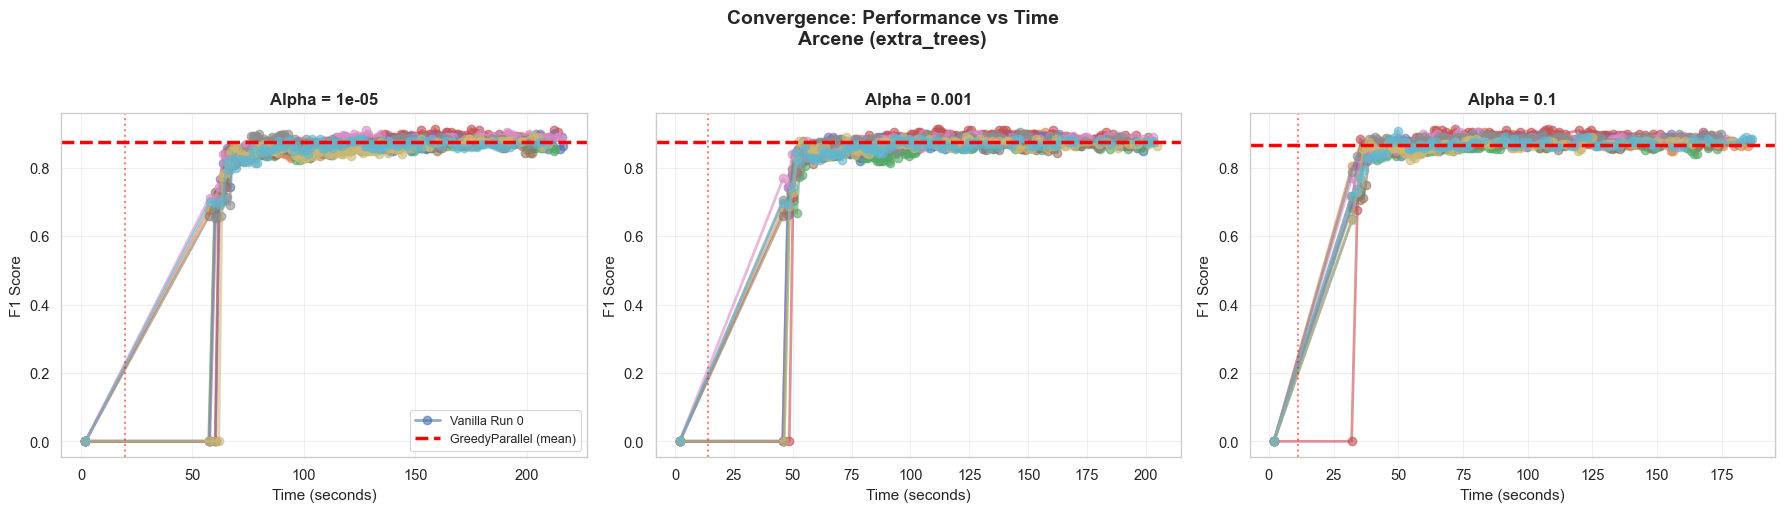

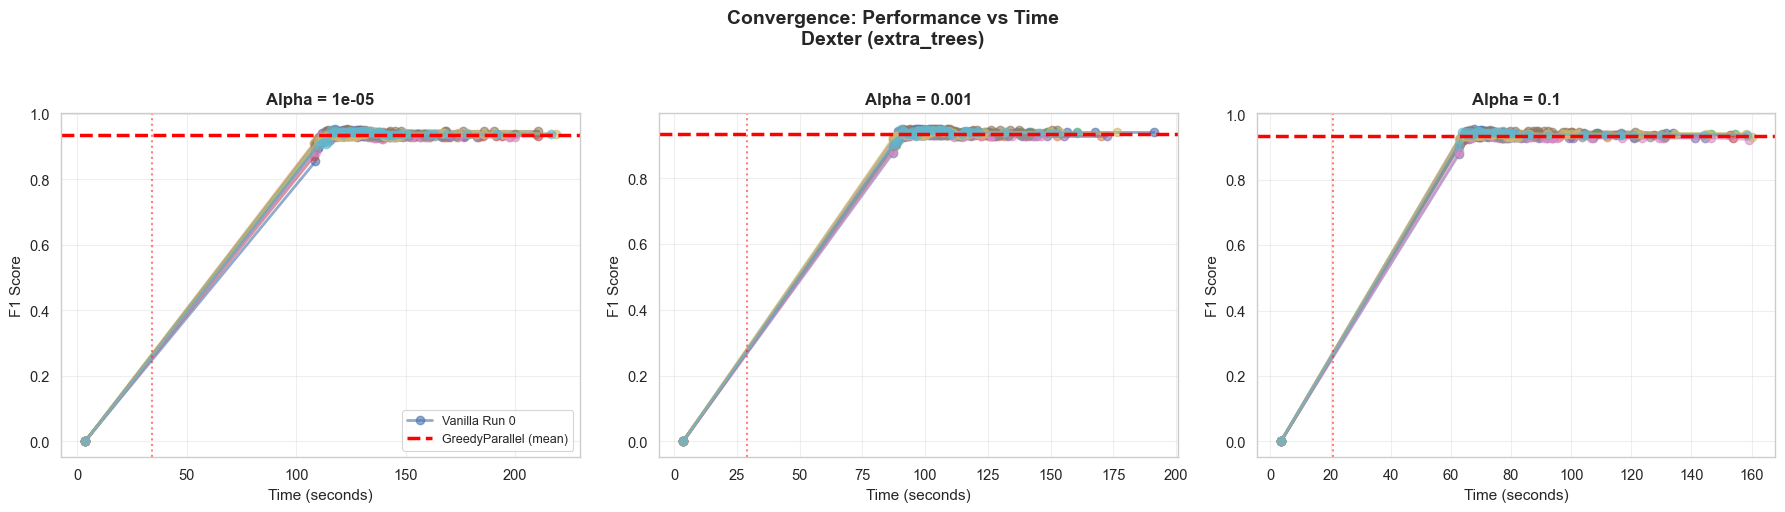

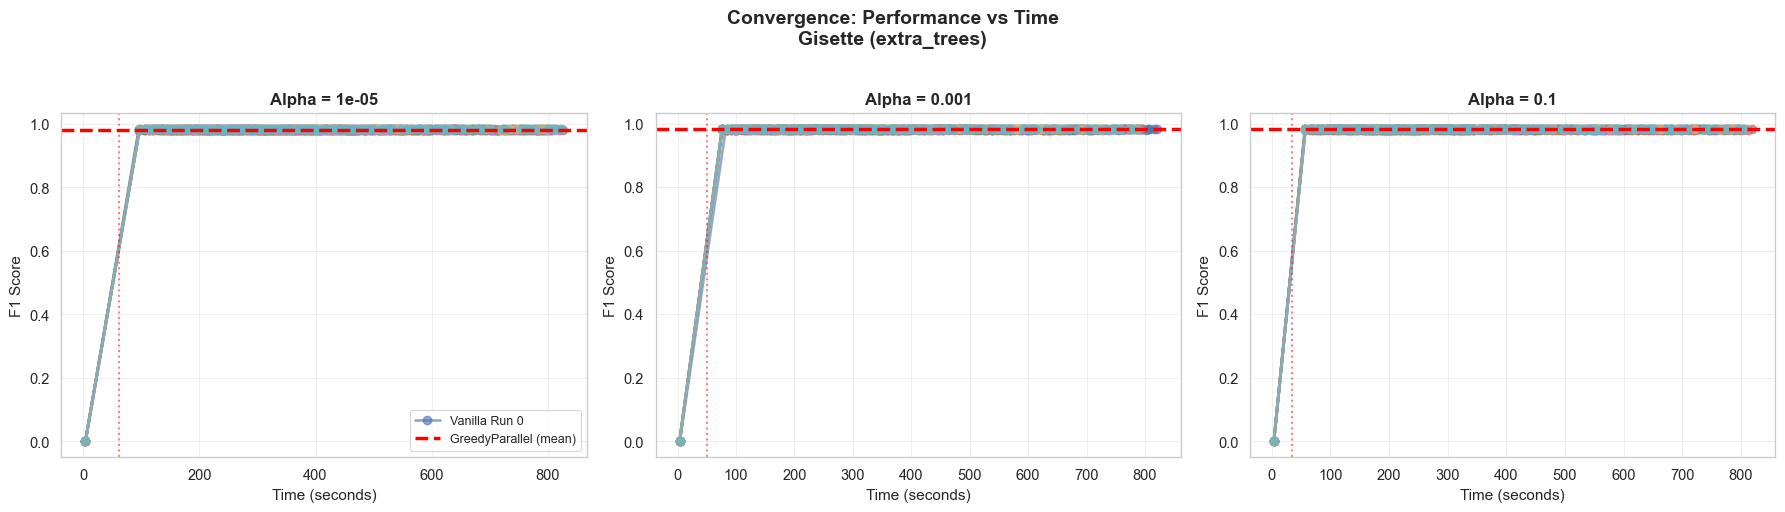

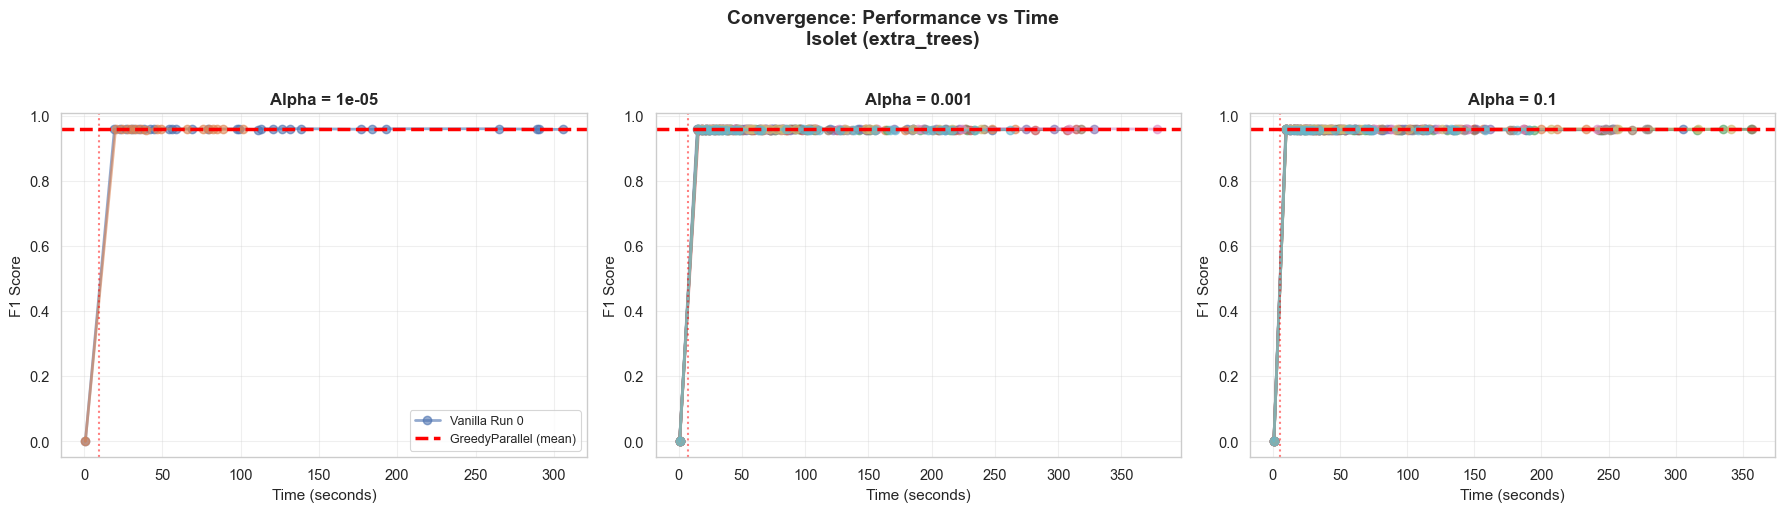

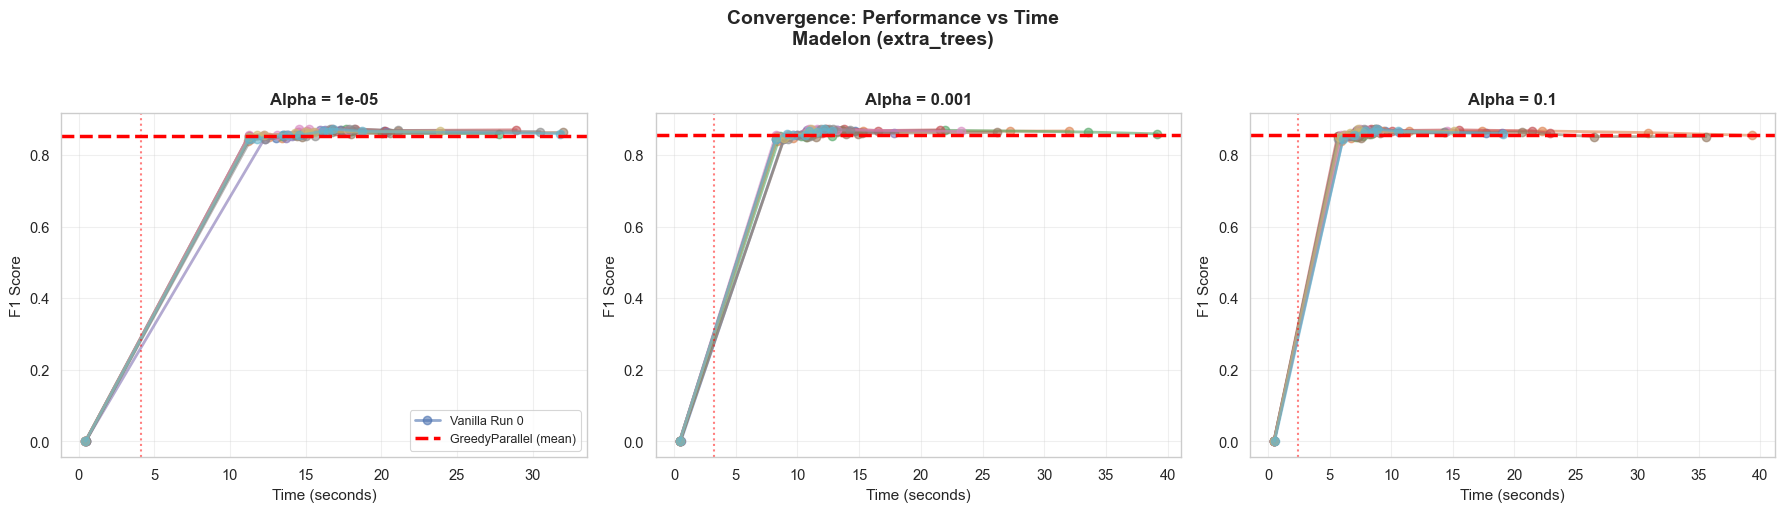

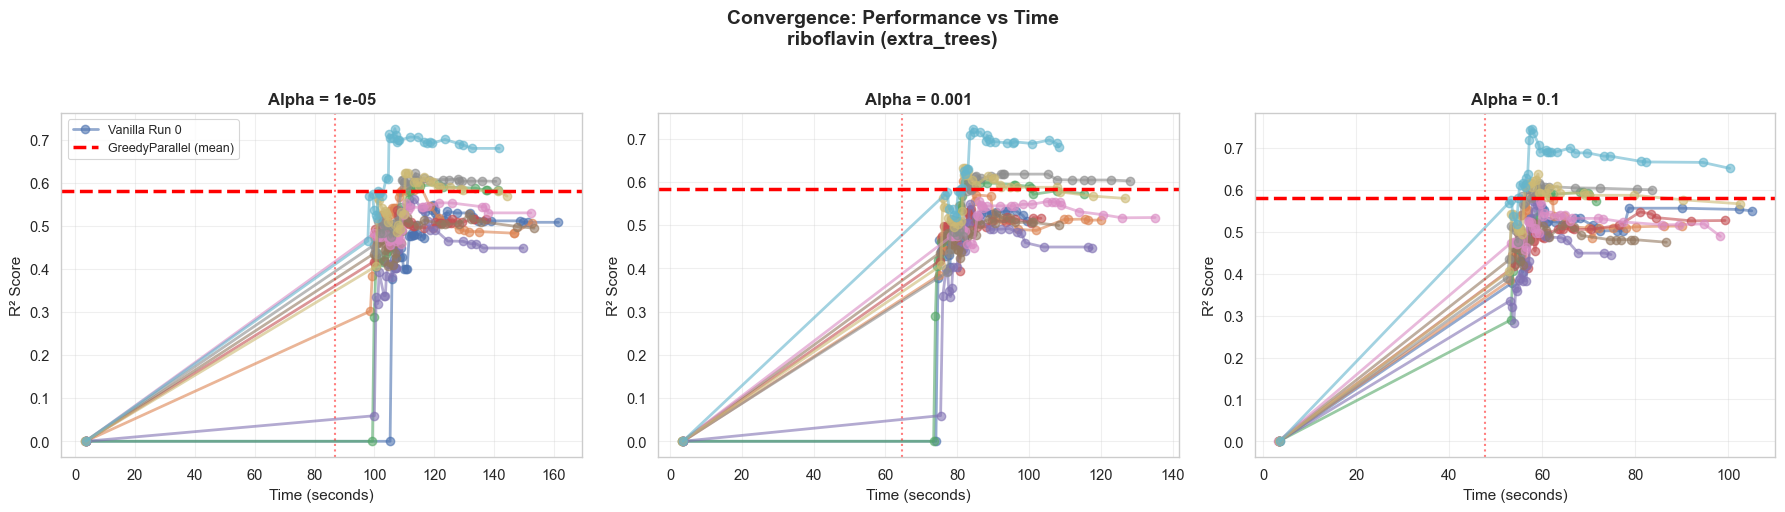

In [7]:
def plot_convergence_vs_time(dataset, estimator):
    """
    Create subplots for each alpha value showing performance vs time.
    Each subplot shows Vanilla checkpoint trajectory and Greedy final result.
    """
    # Filter data for this dataset
    checkpoints = df_checkpoints_filtered[
        df_checkpoints_filtered['Dataset'] == dataset
    ].copy()
    
    greedy_data = df_greedy[
        df_greedy['Dataset'] == dataset
    ].copy()
    
    if len(checkpoints) == 0 or len(greedy_data) == 0:
        print(f"No data for {dataset}")
        return
    
    # Get task type for y-axis label
    task_type = checkpoints['Task'].iloc[0]
    score_label = 'F1 Score' if task_type == 'class' else 'R² Score'
    
    # Create subplots for each alpha
    n_alphas = len(alphas)
    fig, axes = plt.subplots(1, n_alphas, figsize=(6*n_alphas, 5), squeeze=False)
    axes = axes.flatten()
    
    for idx, alpha in enumerate(alphas):
        ax = axes[idx]
        
        # Get checkpoint data for this alpha
        cp_alpha = checkpoints[checkpoints['Alpha'] == alpha]
        greedy_alpha = greedy_data[greedy_data['Alpha'] == alpha]
        
        if len(cp_alpha) == 0:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'Alpha = {alpha}')
            continue
        
        # Plot each run's checkpoint trajectory
        for run_id in cp_alpha['Run_ID'].unique():
            run_data = cp_alpha[cp_alpha['Run_ID'] == run_id].sort_values('Checkpoint_ID')
            ax.plot(run_data['Elapsed_Sec'], run_data['Score_Mean'], 
                   marker='o', alpha=0.6, linewidth=2, markersize=6,
                   label=f'Vanilla Run {run_id}' if idx == 0 and run_id == 0 else '')
        
        # Plot Greedy results as horizontal line
        if len(greedy_alpha) > 0:
            greedy_mean = greedy_alpha['Score_Confirmed_Mean'].mean()
            greedy_time = greedy_alpha['Time_Sec'].mean()
            
            ax.axhline(y=greedy_mean, color='red', linestyle='--', linewidth=2.5,
                      label=f'{greedy_label} (mean)' if idx == 0 else '')
            
            # Mark Greedy's time with a vertical line
            ax.axvline(x=greedy_time, color='red', linestyle=':', alpha=0.5, linewidth=1.5)
        
        ax.set_xlabel('Time (seconds)', fontsize=11)
        ax.set_ylabel(score_label, fontsize=11)
        ax.set_title(f'Alpha = {alpha}', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if idx == 0:
            ax.legend(loc='best', fontsize=9)
    
    fig.suptitle(f'Convergence: Performance vs Time\n{dataset} ({estimator})', 
                fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Generate plots for each dataset
for dataset in datasets:
    plot_convergence_vs_time(dataset, TARGET_ESTIMATOR)

## 4. Convergence Plots: Performance vs Iteration

Same plots as above but with iteration number on the X-axis instead of time.

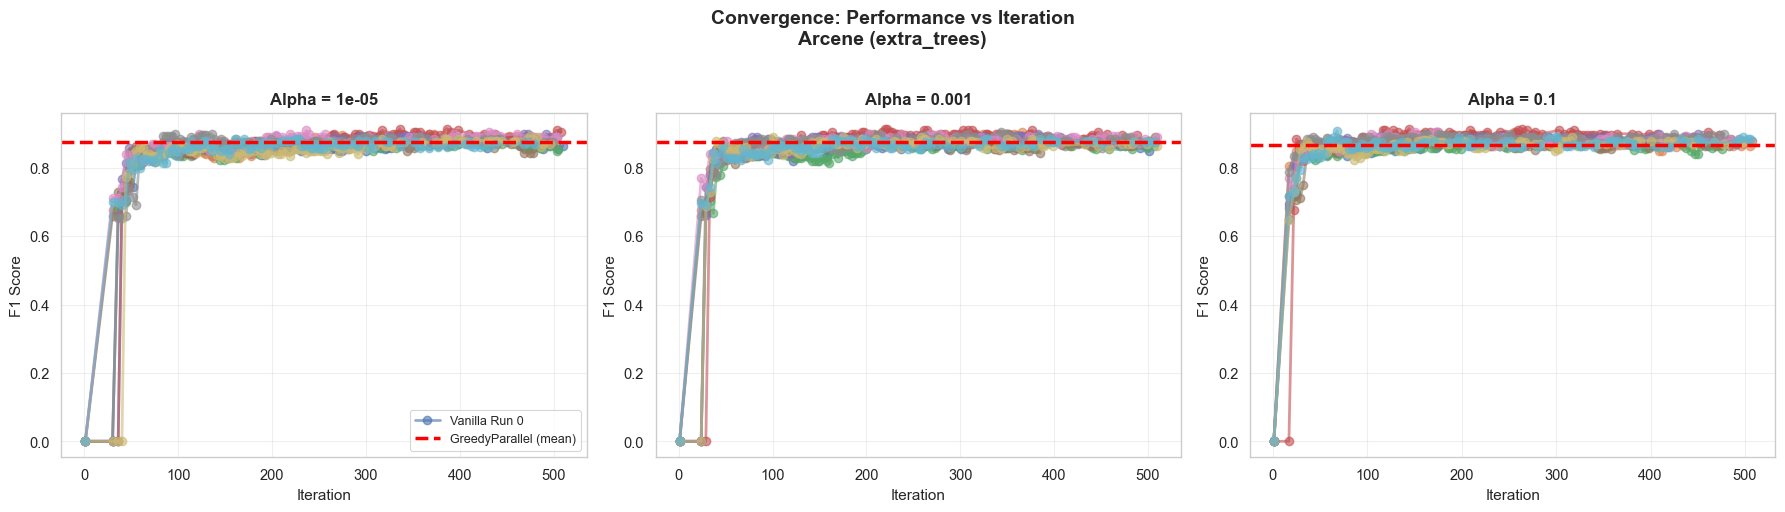

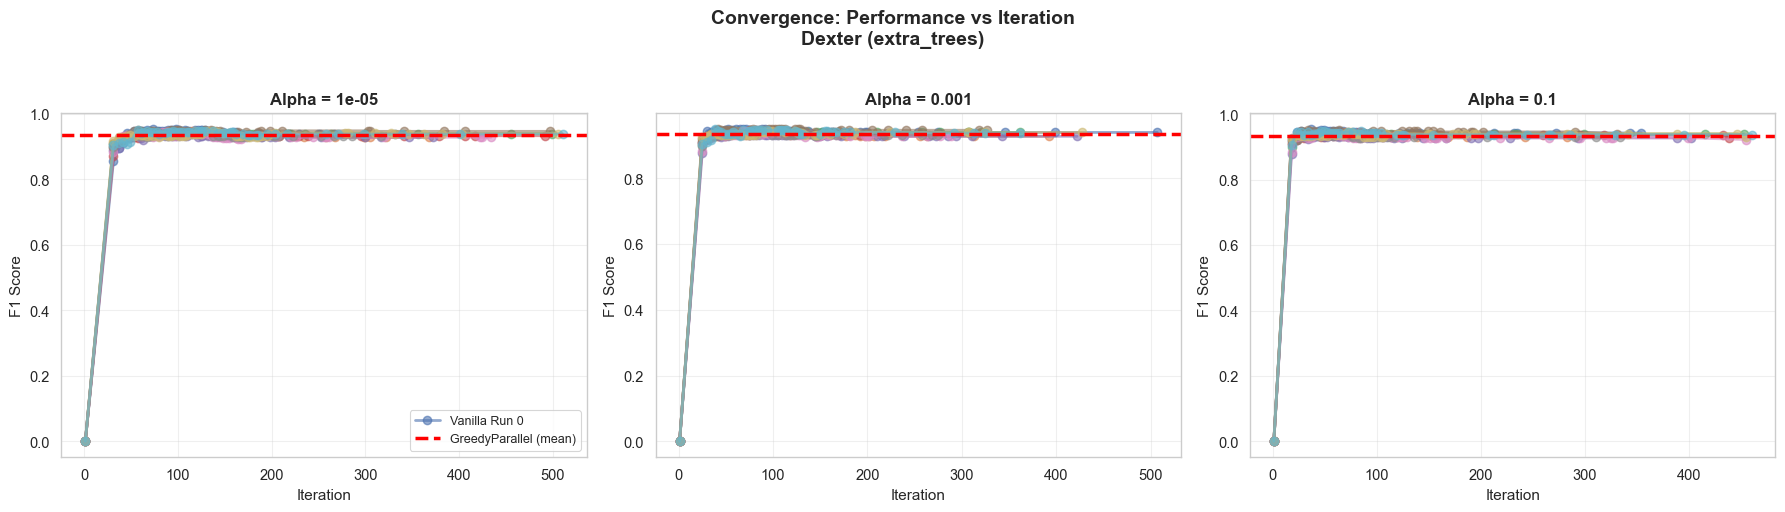

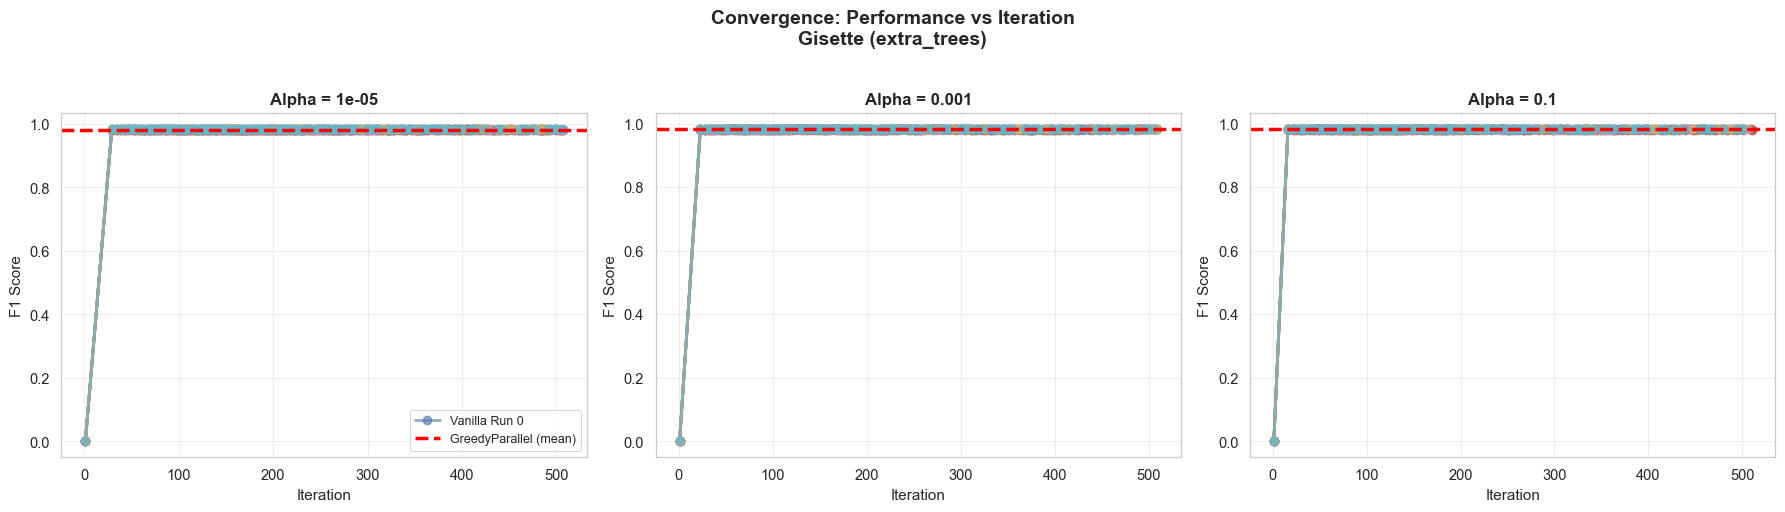

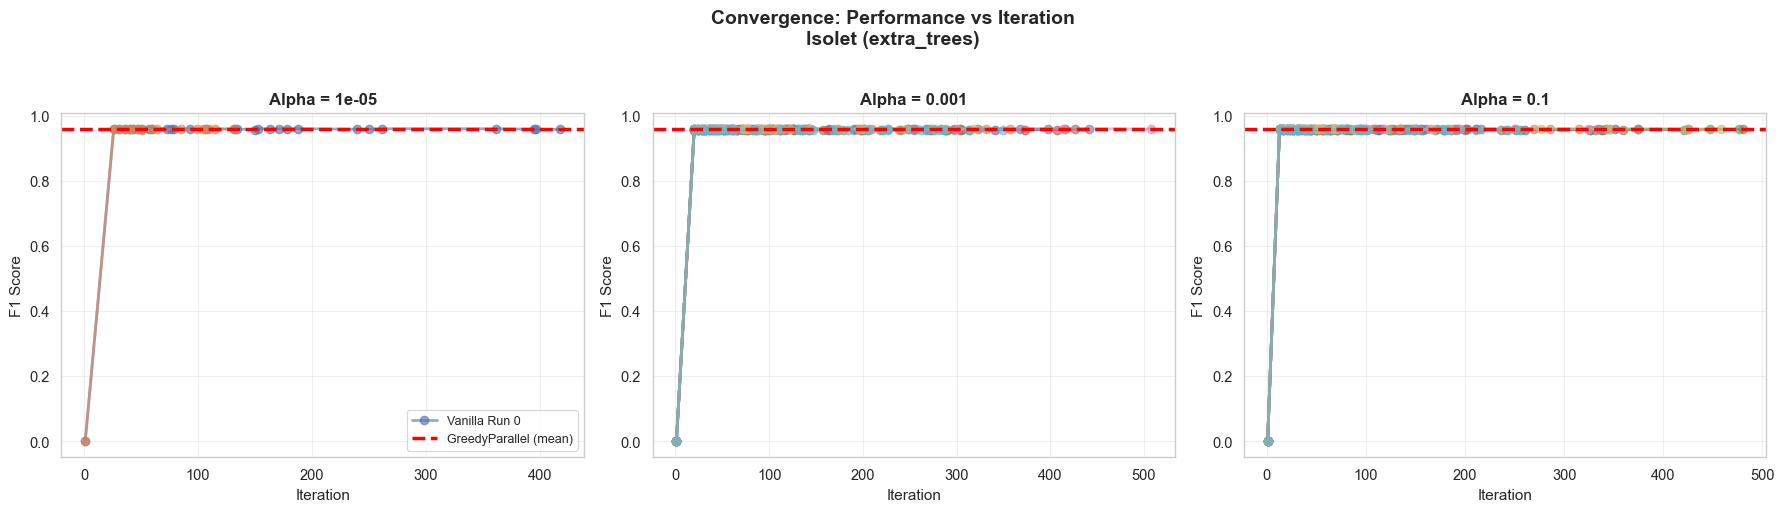

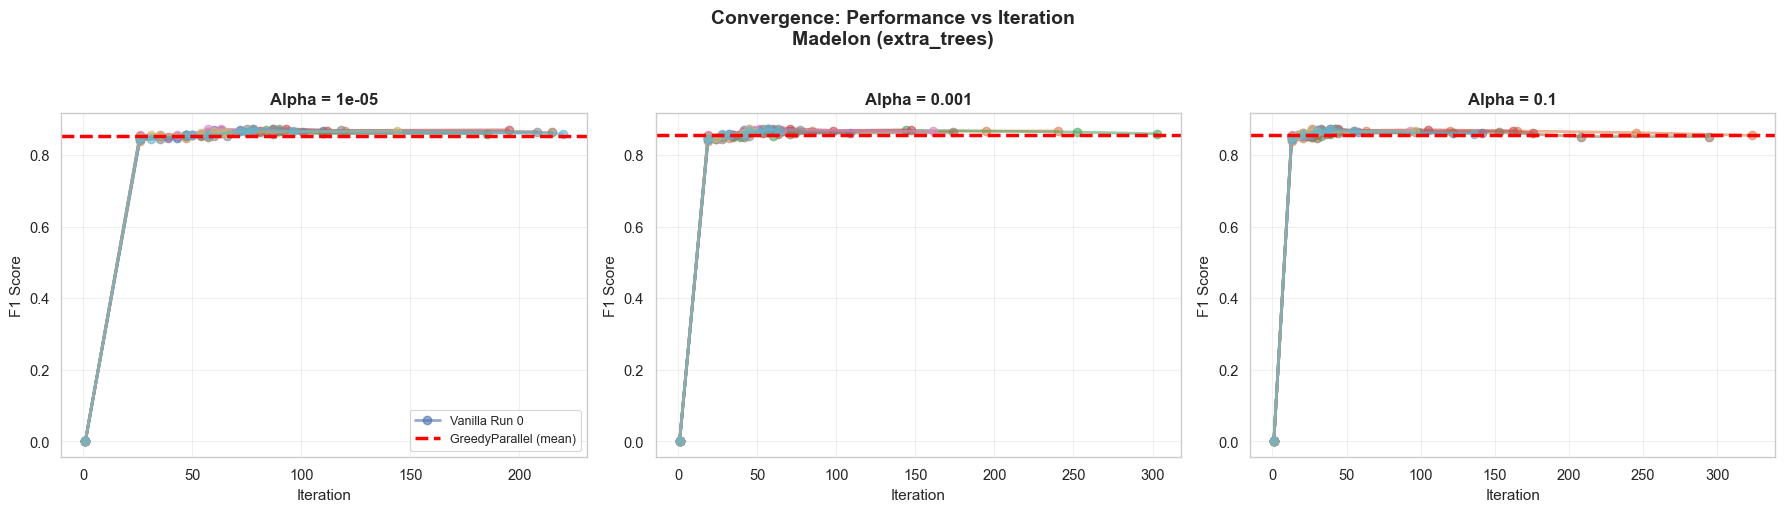

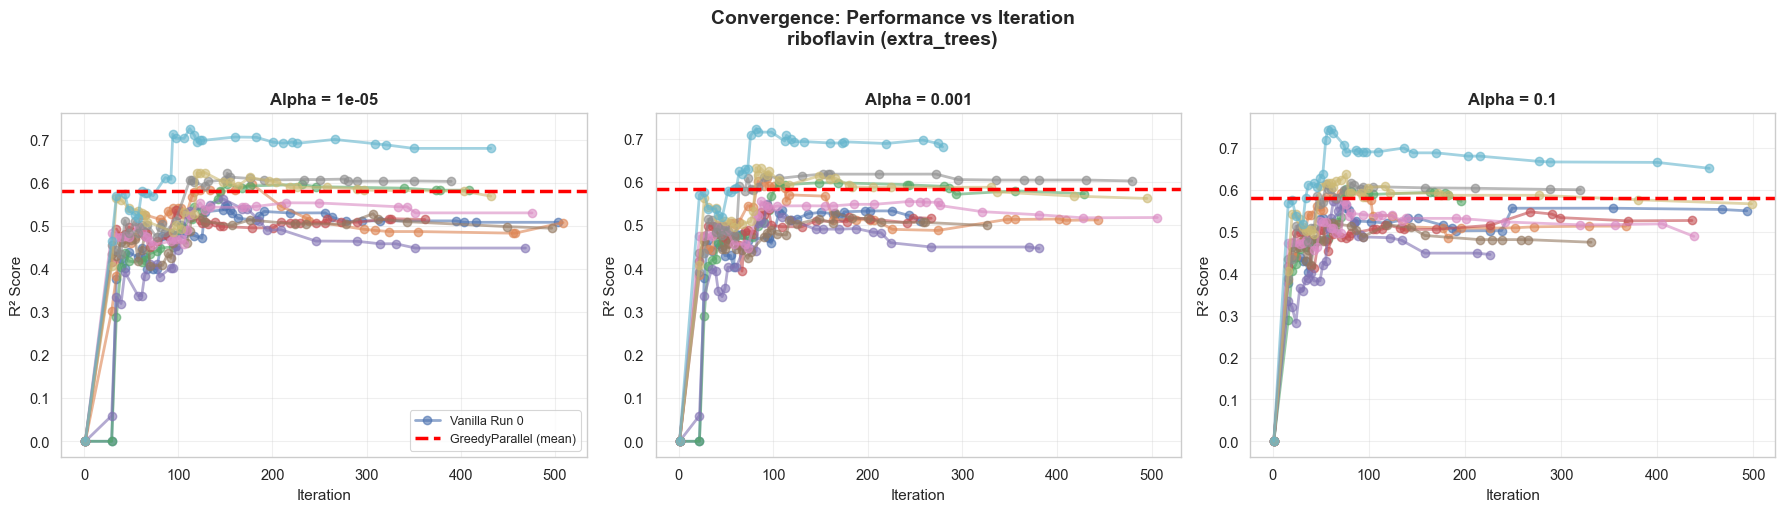

In [8]:
def plot_convergence_vs_iteration(dataset, estimator):
    """
    Create subplots for each alpha value showing performance vs iteration.
    """
    # Filter data for this dataset
    checkpoints = df_checkpoints_filtered[
        df_checkpoints_filtered['Dataset'] == dataset
    ].copy()
    
    greedy_data = df_greedy[
        df_greedy['Dataset'] == dataset
    ].copy()
    
    if len(checkpoints) == 0 or len(greedy_data) == 0:
        print(f"No data for {dataset}")
        return
    
    # Get task type for y-axis label
    task_type = checkpoints['Task'].iloc[0]
    score_label = 'F1 Score' if task_type == 'class' else 'R² Score'
    
    # Create subplots for each alpha
    n_alphas = len(alphas)
    fig, axes = plt.subplots(1, n_alphas, figsize=(6*n_alphas, 5), squeeze=False)
    axes = axes.flatten()
    
    for idx, alpha in enumerate(alphas):
        ax = axes[idx]
        
        # Get checkpoint data for this alpha
        cp_alpha = checkpoints[checkpoints['Alpha'] == alpha]
        greedy_alpha = greedy_data[greedy_data['Alpha'] == alpha]
        
        if len(cp_alpha) == 0:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'Alpha = {alpha}')
            continue
        
        # Plot each run's checkpoint trajectory
        for run_id in cp_alpha['Run_ID'].unique():
            run_data = cp_alpha[cp_alpha['Run_ID'] == run_id].sort_values('Checkpoint_ID')
            ax.plot(run_data['Iteration'], run_data['Score_Mean'], 
                   marker='o', alpha=0.6, linewidth=2, markersize=6,
                   label=f'Vanilla Run {run_id}' if idx == 0 and run_id == 0 else '')
        
        # Plot Greedy results as horizontal line
        if len(greedy_alpha) > 0:
            greedy_mean = greedy_alpha['Score_Confirmed_Mean'].mean()
            
            ax.axhline(y=greedy_mean, color='red', linestyle='--', linewidth=2.5,
                      label=f'{greedy_label} (mean)' if idx == 0 else '')
        
        ax.set_xlabel('Iteration', fontsize=11)
        ax.set_ylabel(score_label, fontsize=11)
        ax.set_title(f'Alpha = {alpha}', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if idx == 0:
            ax.legend(loc='best', fontsize=9)
    
    fig.suptitle(f'Convergence: Performance vs Iteration\n{dataset} ({estimator})', 
                fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Generate plots for each dataset
for dataset in datasets:
    plot_convergence_vs_iteration(dataset, TARGET_ESTIMATOR)

# 4b. Undecideness Factor 

UNDECIDEDNESS FACTOR: Proportion of Tentative Features

Plotting undecidedness factor vs iteration...


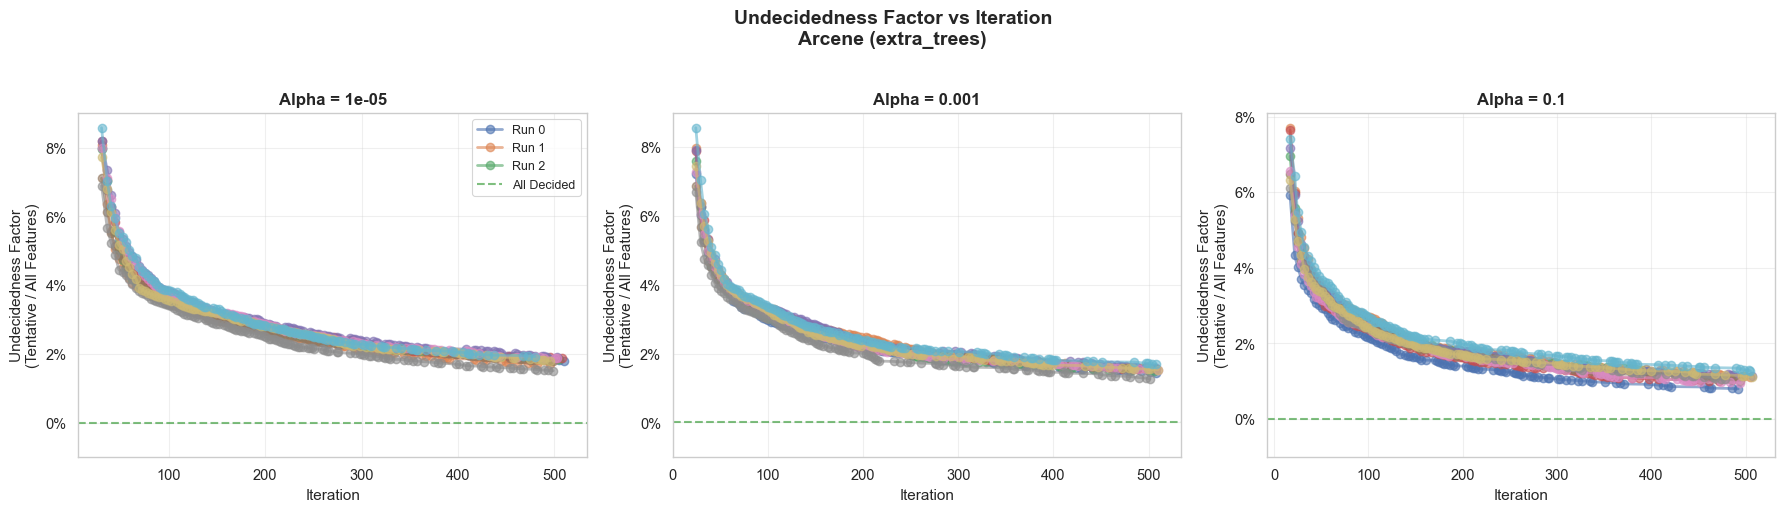

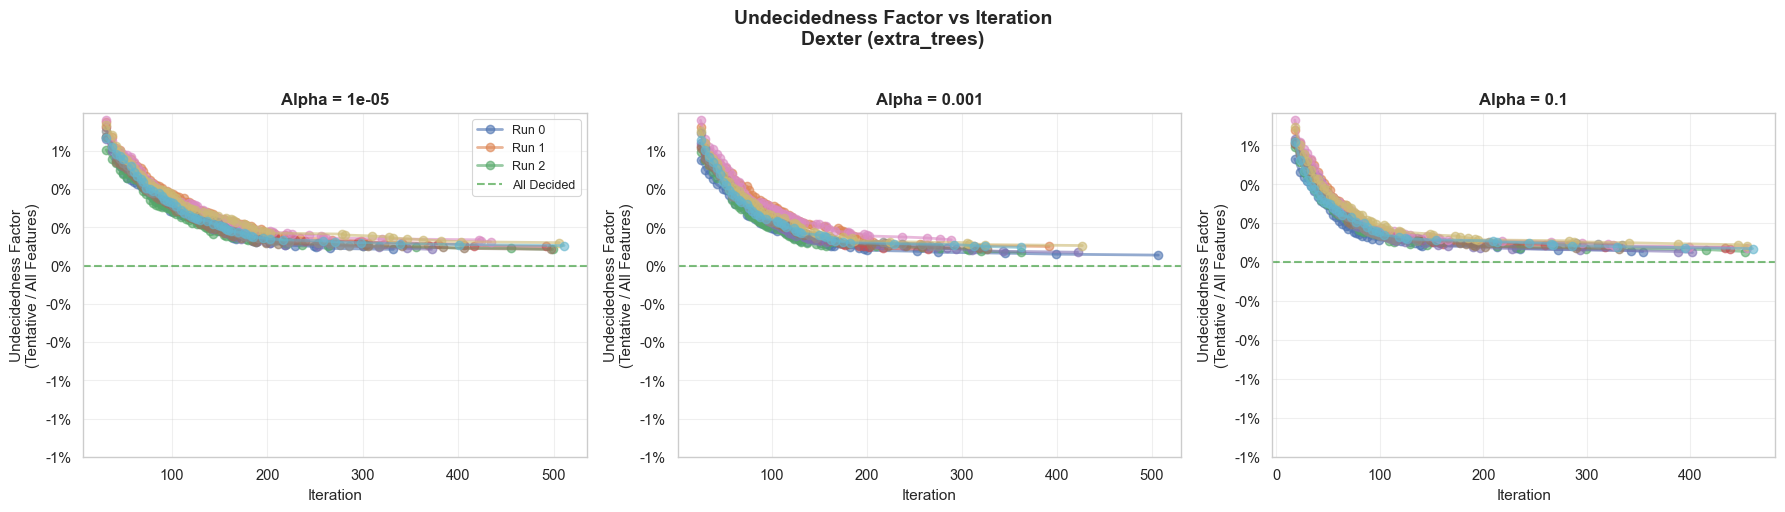

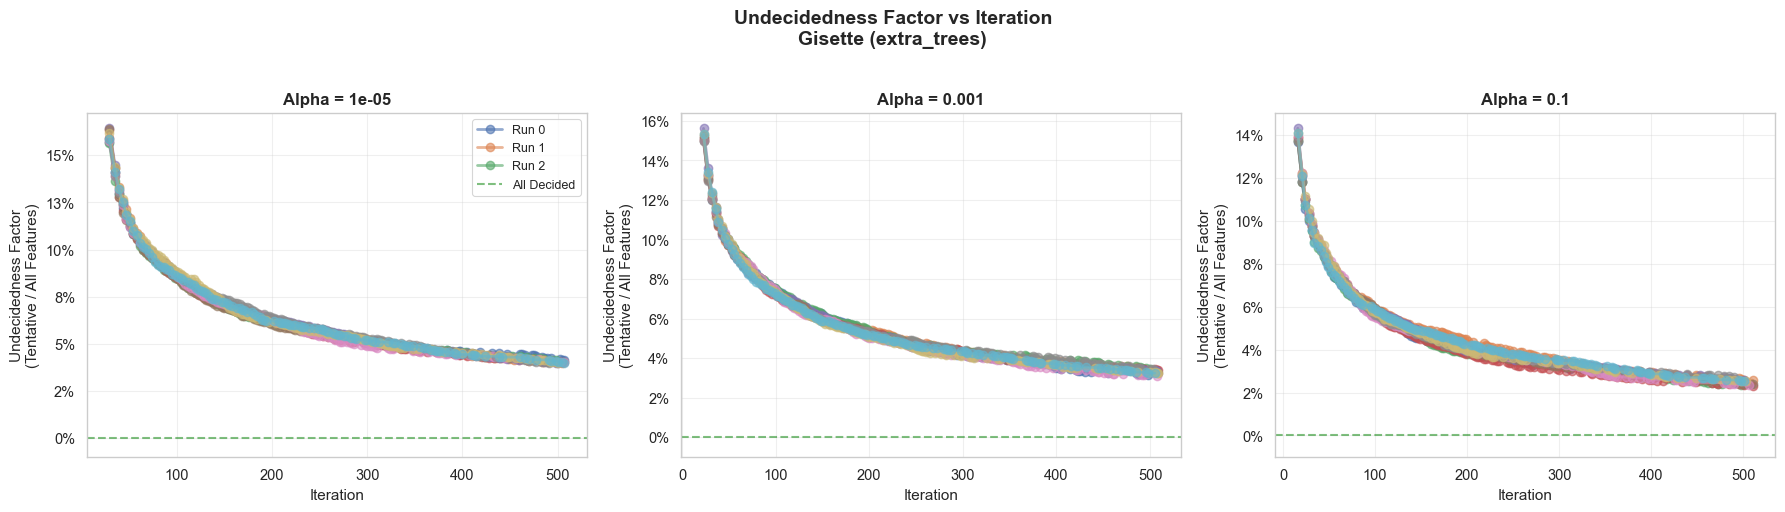

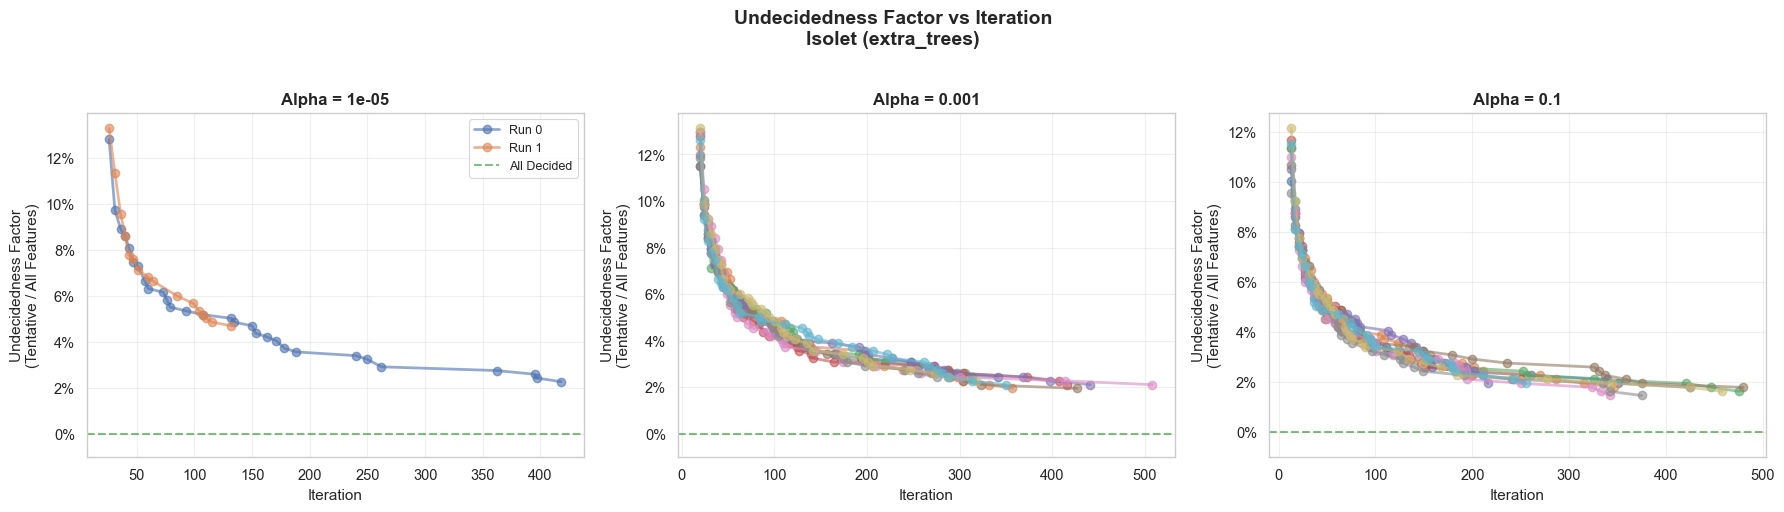

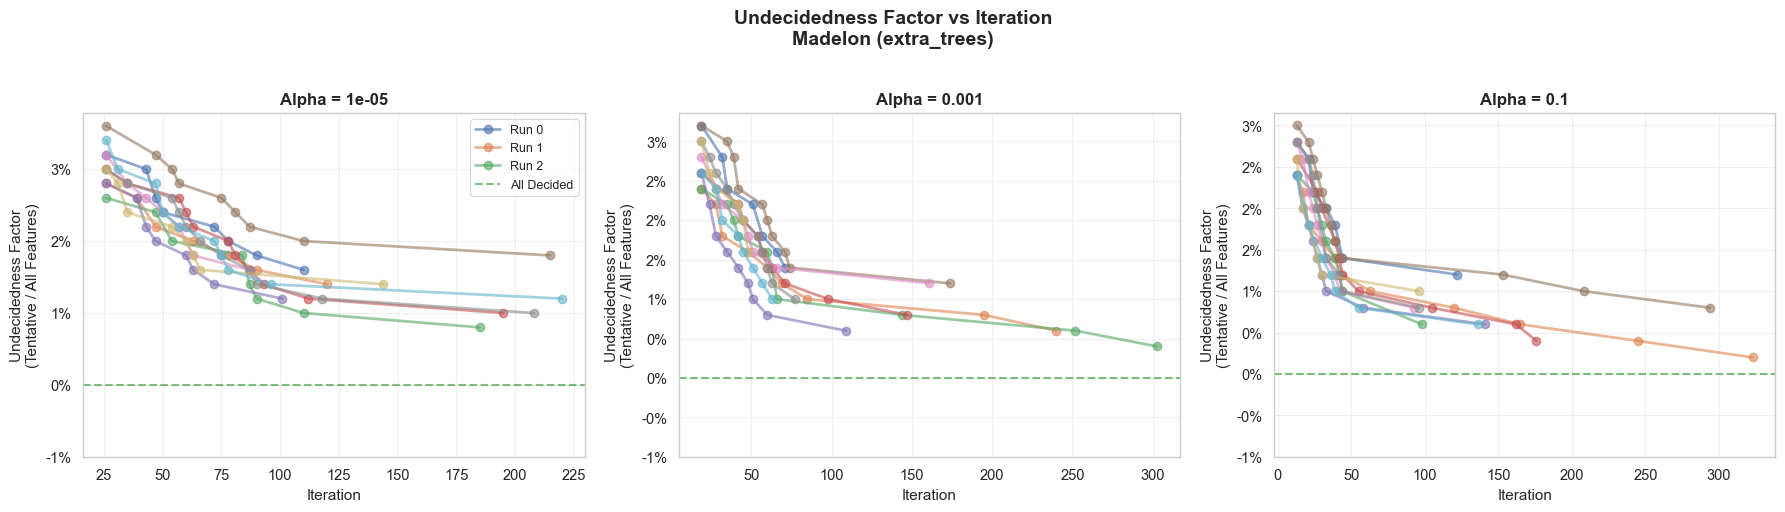

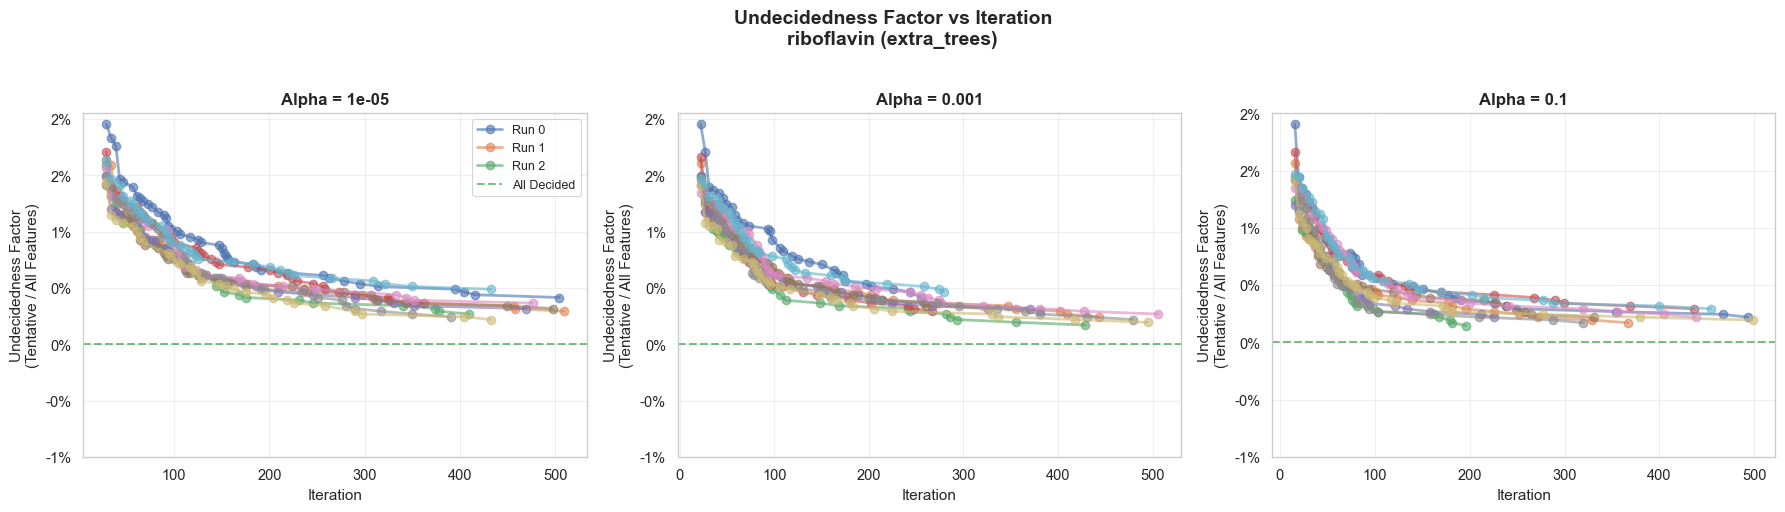

In [9]:
def plot_undecideness_factor(dataset, estimator, x_axis='time'):
    """
    Create subplots showing the proportion of tentative features over time or iterations.

    Parameters
    ----------
    dataset : str
        Dataset name
    estimator : str
        Estimator type
    x_axis : str, default='time'
        'time' for elapsed time, 'iteration' for iteration number
    """
    # Filter data for this dataset
    checkpoints = df_checkpoints_filtered[
        df_checkpoints_filtered['Dataset'] == dataset
    ].copy()

    if len(checkpoints) == 0:
        print(f"No data for {dataset}")
        return

    # Calculate undecidedness factor (tentative / all features)
    all_features = checkpoints['N_Tentative'] + checkpoints['N_Rejected'] + checkpoints['N_Confirmed']
    checkpoints['Undecidedness_Factor'] = np.where(
        all_features > 0,
        checkpoints['N_Tentative'] / all_features,
        np.nan
    )

    # Create subplots for each alpha
    n_alphas = len(alphas)
    fig, axes = plt.subplots(1, n_alphas, figsize=(6*n_alphas, 5), squeeze=False)
    axes = axes.flatten()

    for idx, alpha in enumerate(alphas):
        ax = axes[idx]

        # Get checkpoint data for this alpha
        cp_alpha = checkpoints[checkpoints['Alpha'] == alpha]

        if len(cp_alpha) == 0:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'Alpha = {alpha}')
            continue

        # Determine x-axis values
        if x_axis == 'time':
            x_col = 'Elapsed_Sec'
            x_label = 'Time (seconds)'
        else:
            x_col = 'Iteration'
            x_label = 'Iteration'

        # Plot each run's undecidedness trajectory
        for run_id in cp_alpha['Run_ID'].unique():
            run_data = cp_alpha[(cp_alpha['Run_ID'] == run_id) & (cp_alpha['Checkpoint_ID'] > 0)].sort_values('Checkpoint_ID')
            ax.plot(run_data[x_col], run_data['Undecidedness_Factor'],
                   marker='o', alpha=0.6, linewidth=2, markersize=6,
                   label=f'Run {run_id}' if idx == 0 and run_id < 3 else '')

        # Add horizontal line at 0 (all decided)
        ax.axhline(y=0, color='green', linestyle='--', linewidth=1.5, alpha=0.5,
                  label='All Decided' if idx == 0 else '')

        ax.set_xlabel(x_label, fontsize=11)
        ax.set_ylabel('Undecidedness Factor\n(Tentative / All Features)', fontsize=11)
        ax.set_title(f'Alpha = {alpha}', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        ax.set_ylim(bottom=-0.01)  # Start slightly below 0 for better visualization

        # Format y-axis as percentage
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

        if idx == 0:
            ax.legend(loc='best', fontsize=9)

    x_type = 'Time' if x_axis == 'time' else 'Iteration'
    fig.suptitle(f'Undecidedness Factor vs {x_type}\n{dataset} ({estimator})',
                fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Generate plots for each dataset - both time and iteration versions
print("=" * 80)
print("UNDECIDEDNESS FACTOR: Proportion of Tentative Features")
print("=" * 80)
# print("\nPlotting undecidedness factor vs time...")
# for dataset in datasets:
#     plot_undecideness_factor(dataset, TARGET_ESTIMATOR, x_axis='time')

print("\nPlotting undecidedness factor vs iteration...")
for dataset in datasets:
    plot_undecideness_factor(dataset, TARGET_ESTIMATOR, x_axis='iteration')

POTENTIAL MISS RATE: Tentative / (Tentative + Confirmed)

This metric shows what proportion of currently decided features are still
tentative (not yet confirmed). Lower is better - it means more features have
been confirmed relative to those still under consideration.

Plotting potential miss rate vs time...


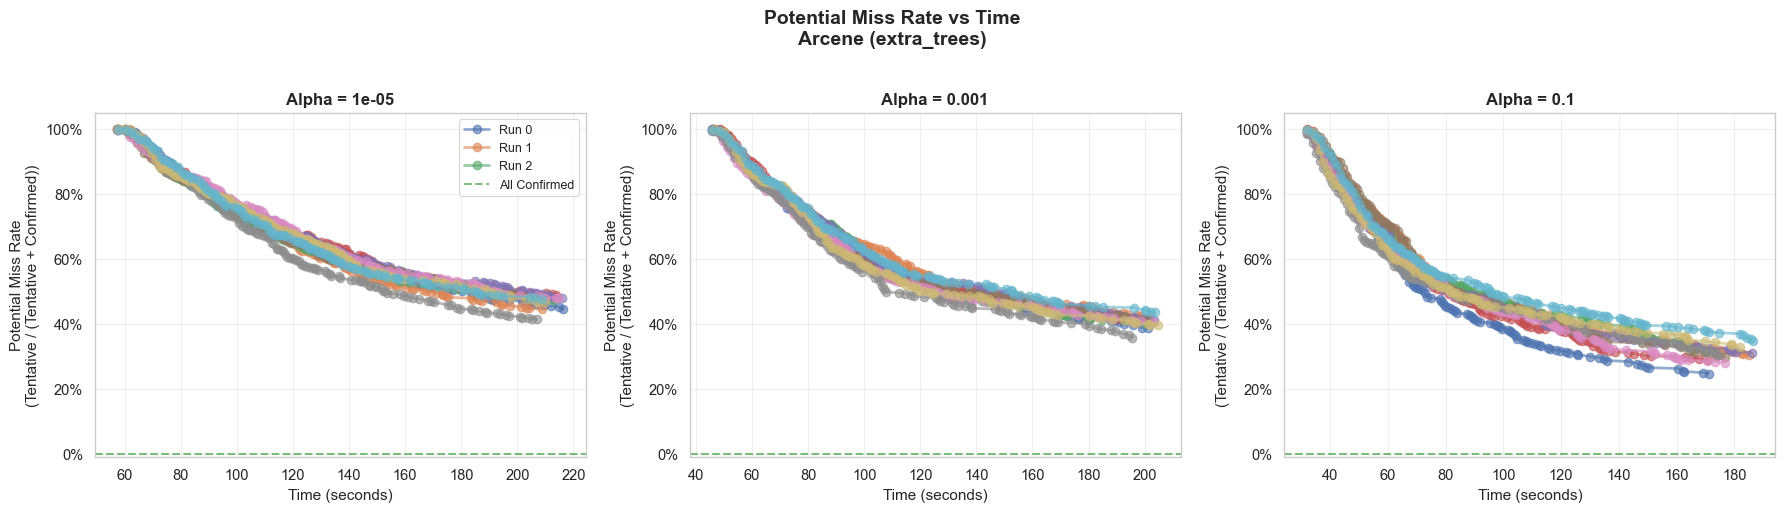

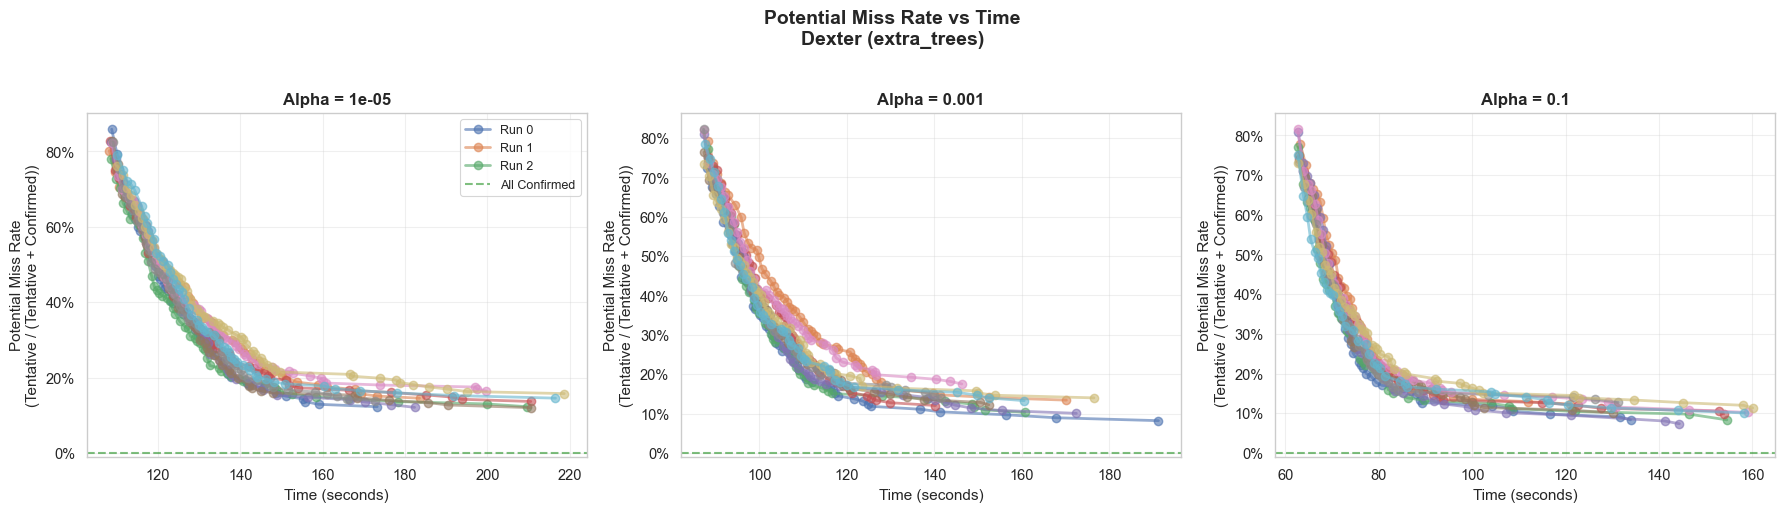

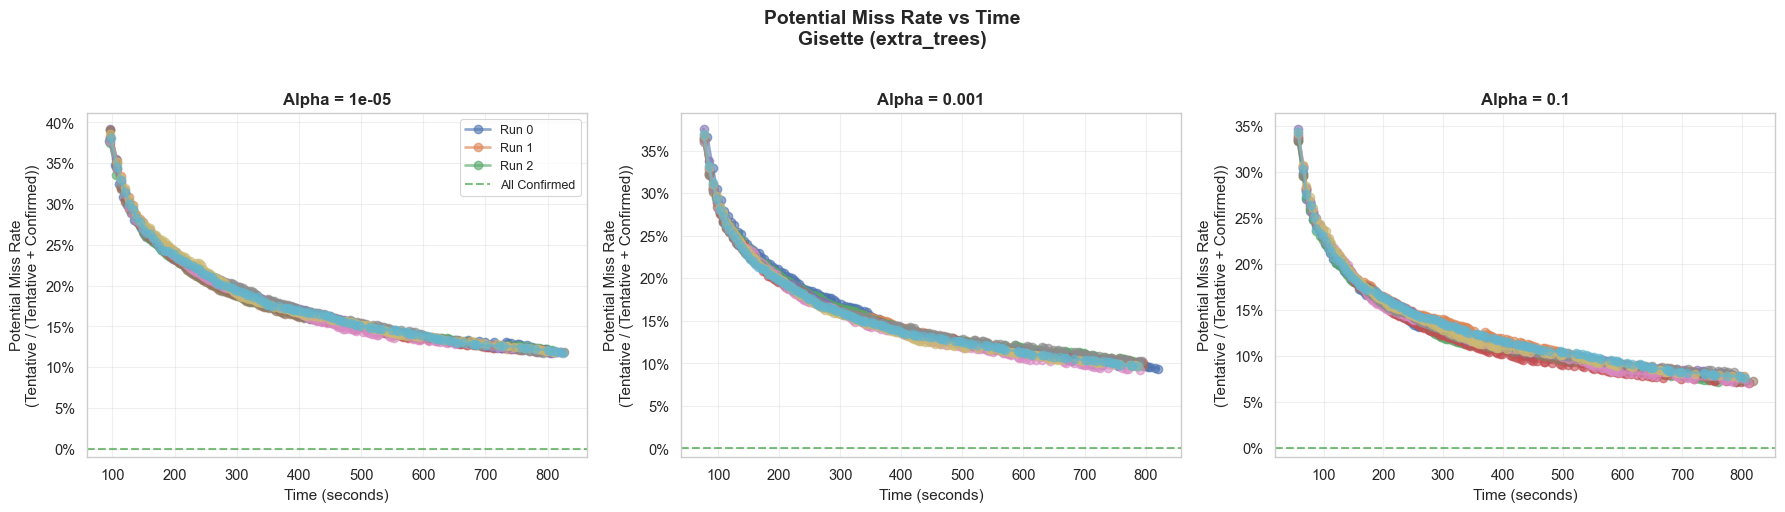

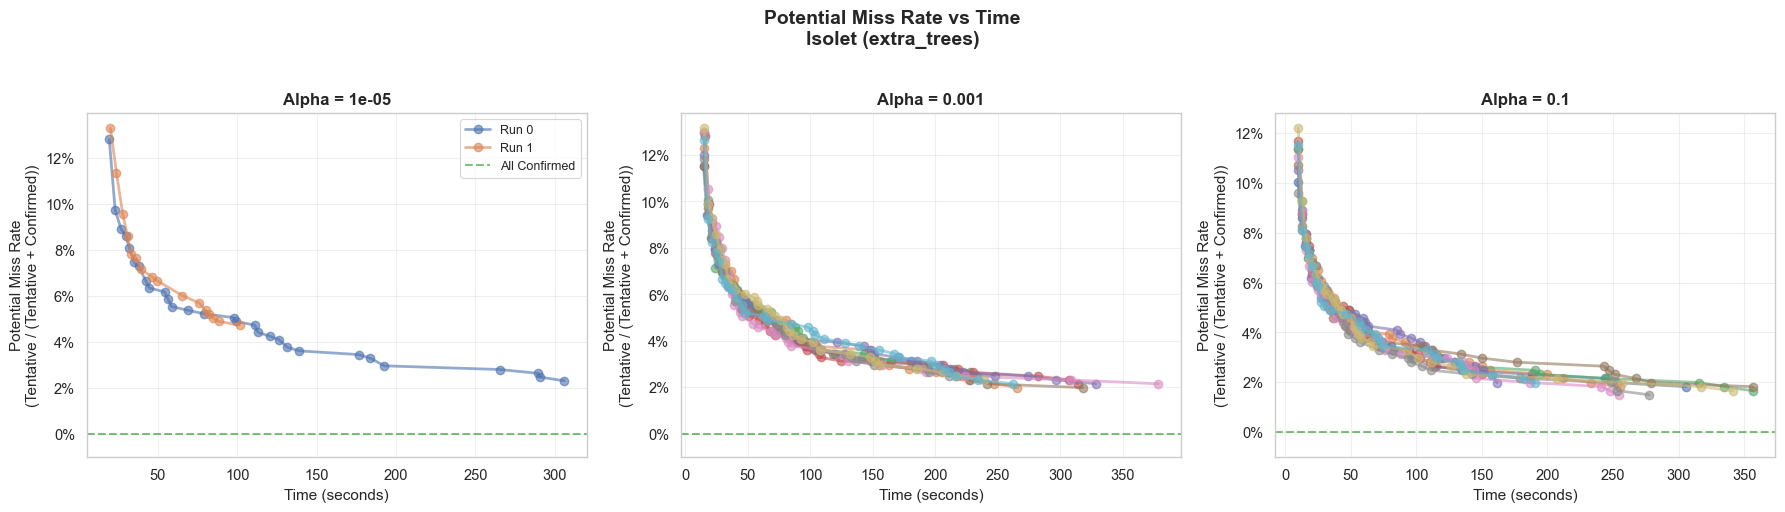

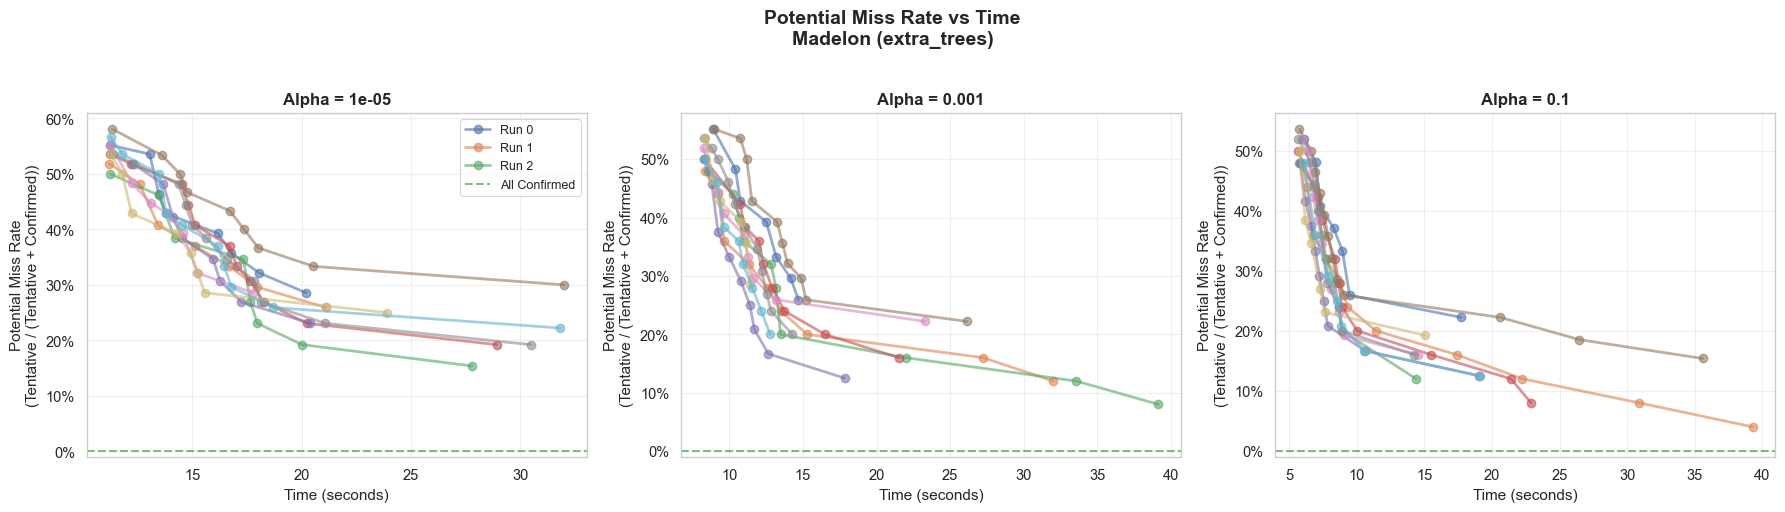

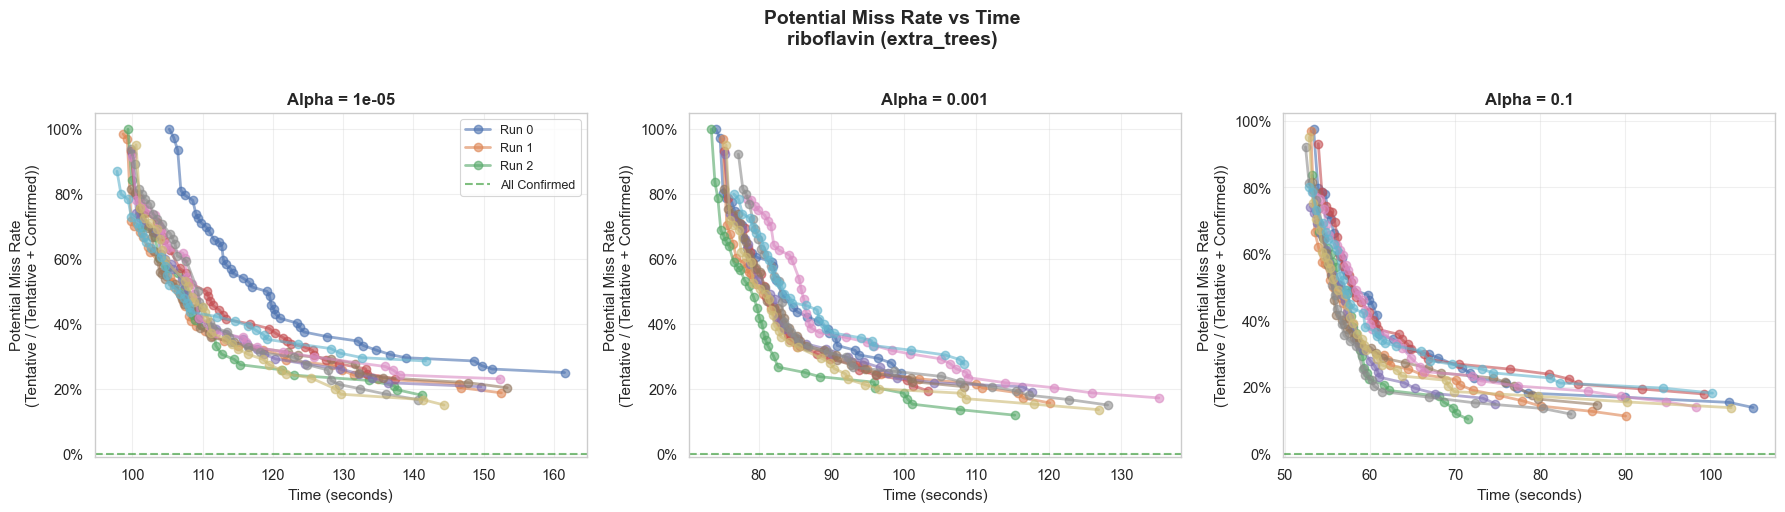


Plotting potential miss rate vs iteration...


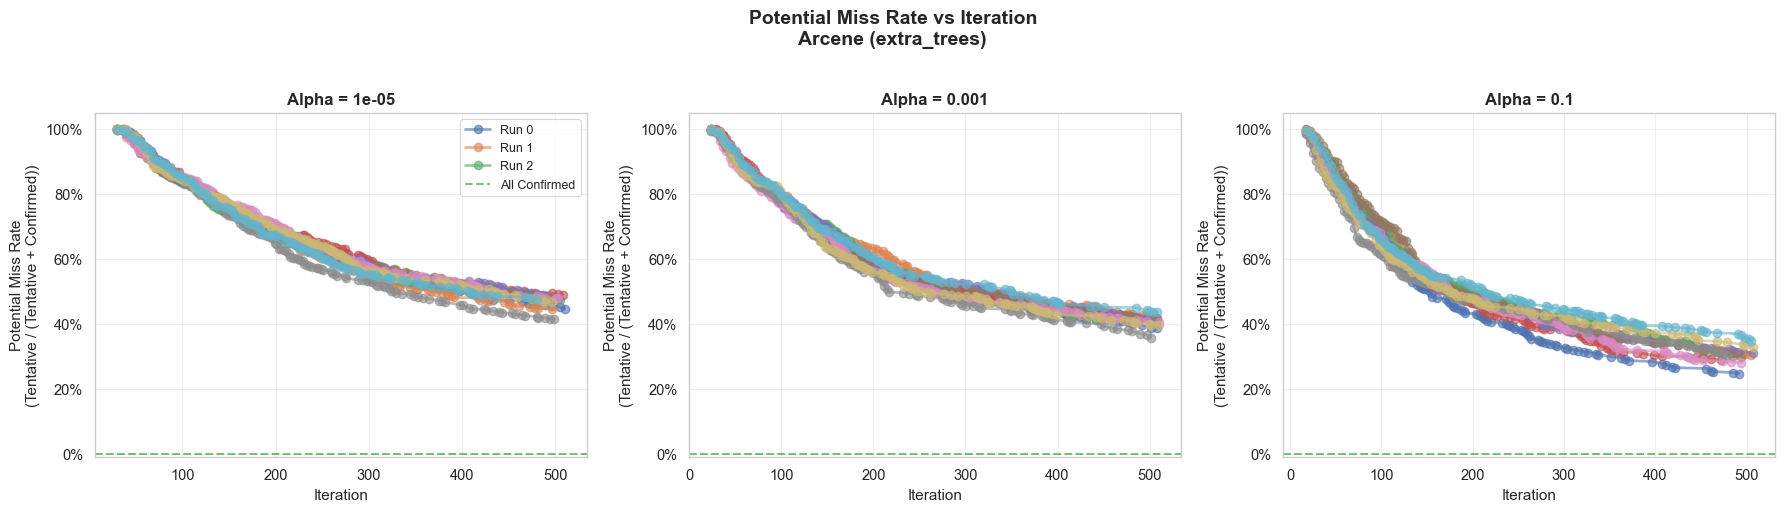

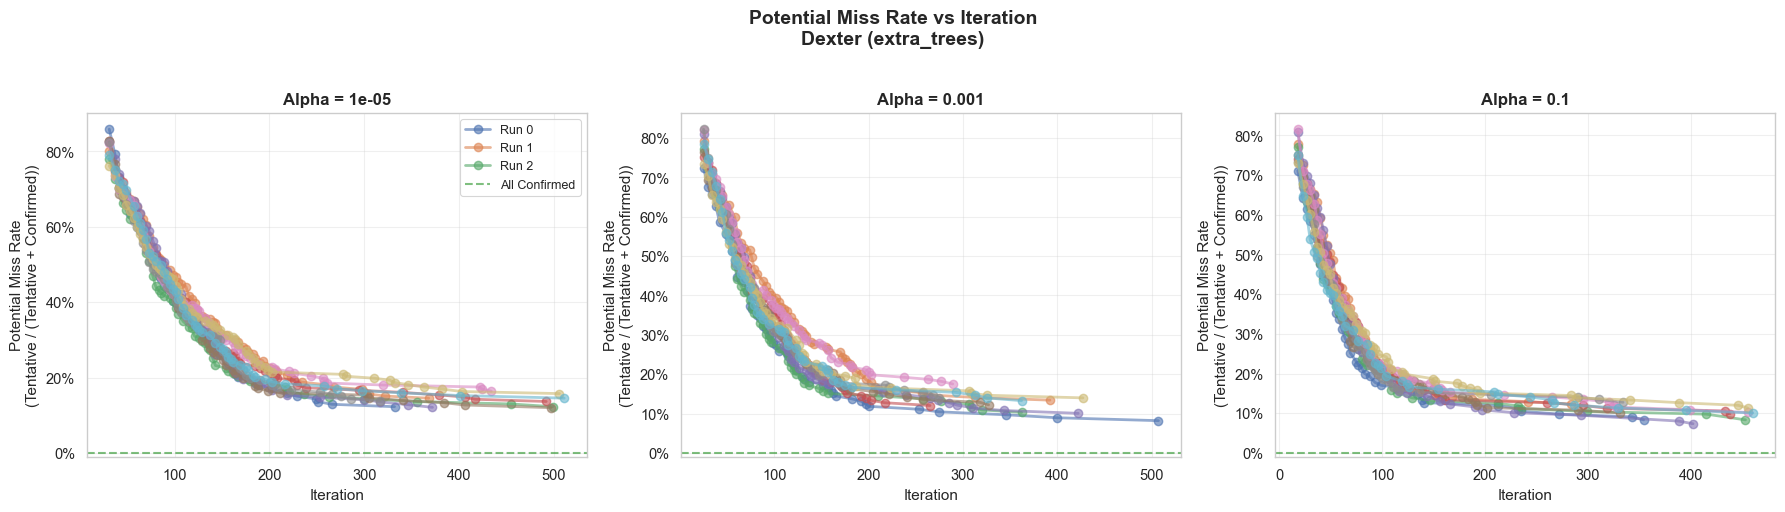

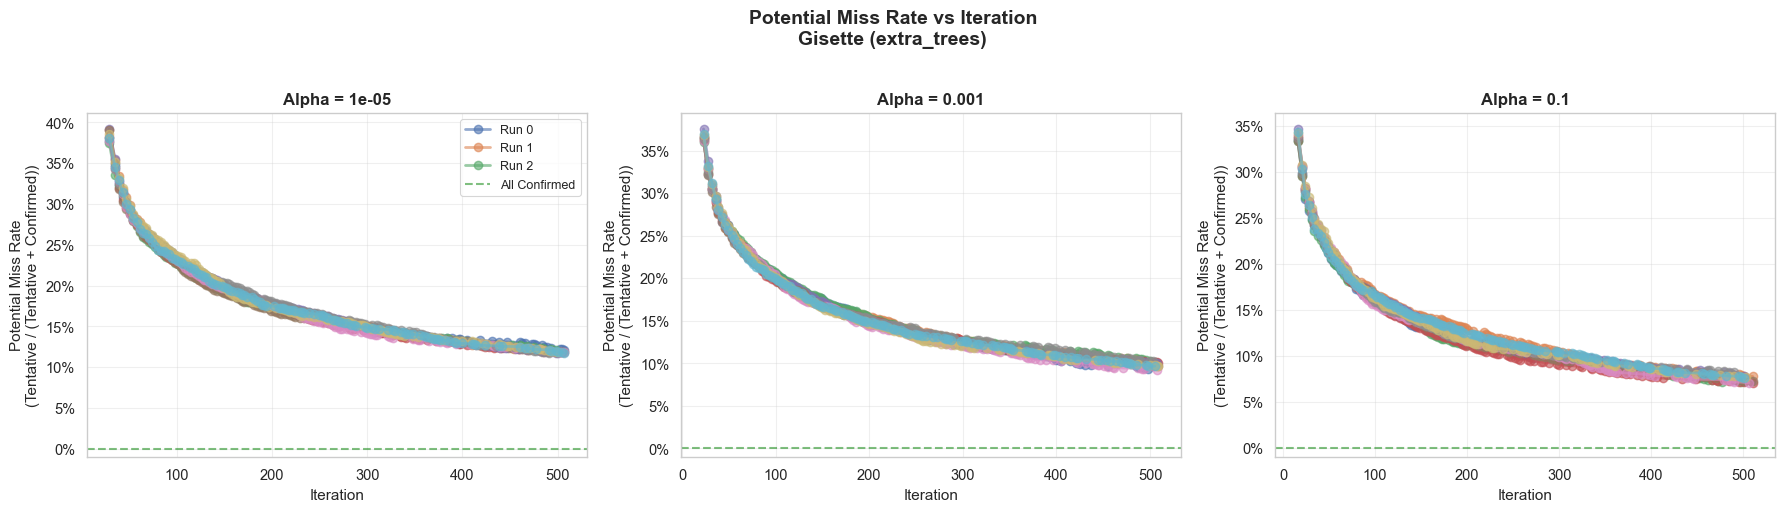

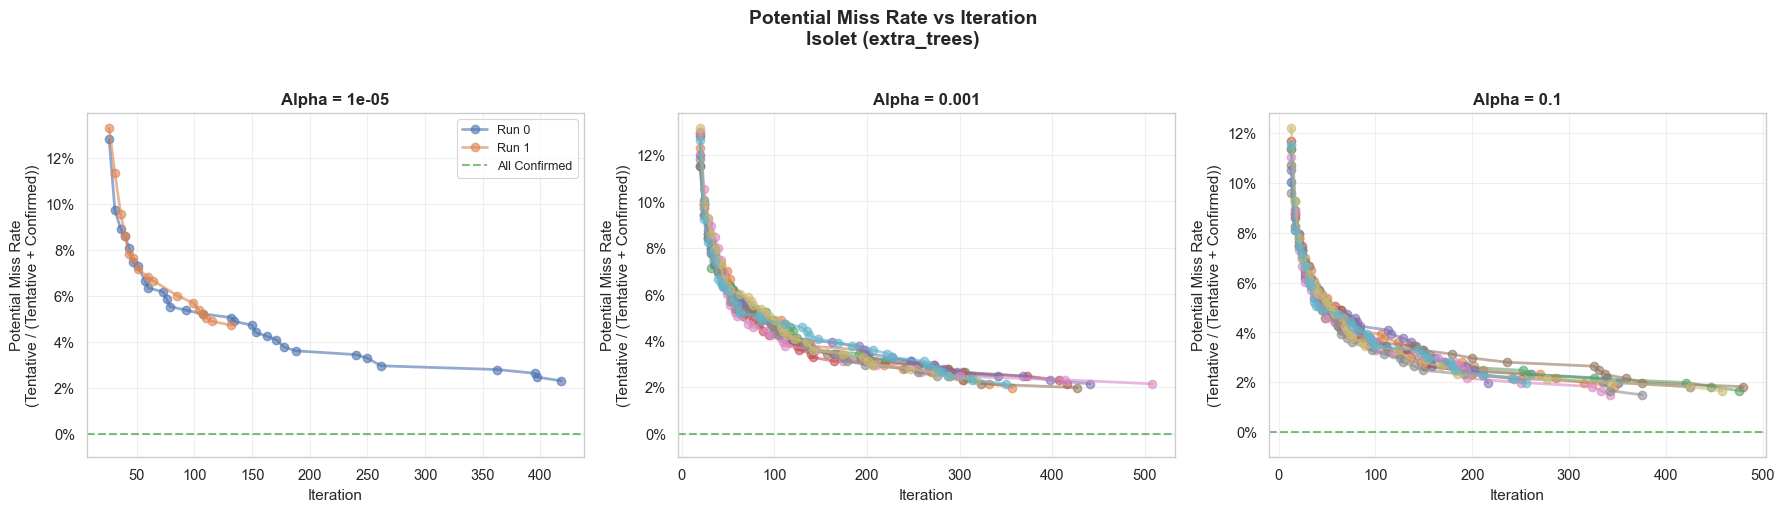

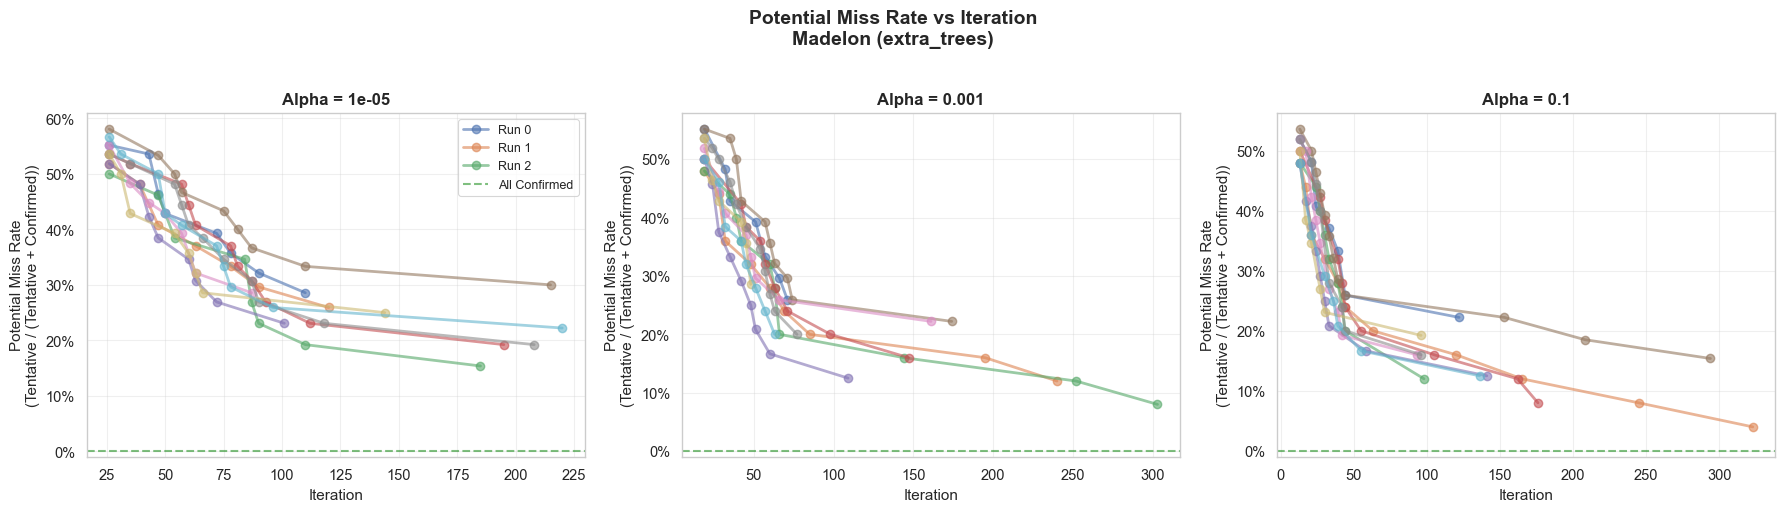

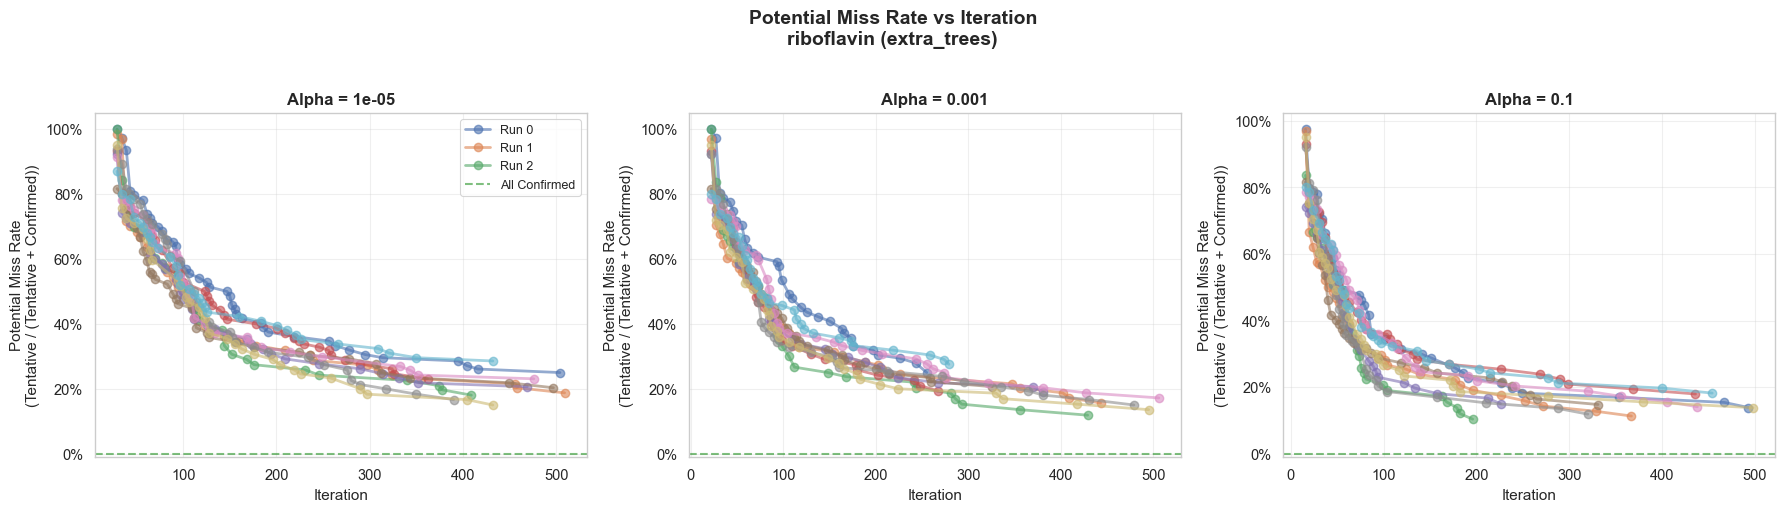

In [10]:
def plot_potential_miss_rate(dataset, estimator, x_axis='time'):
    """
    Create subplots showing the potential miss rate over time or iterations.
    
    Potential Miss Rate = N_Tentative / (N_Tentative + N_Confirmed)
    
    This metric represents the proportion of currently decided features that are
    still tentative (not yet confirmed). A high rate means many features are
    undecided relative to confirmed features.

    Parameters
    ----------
    dataset : str
        Dataset name
    estimator : str
        Estimator type
    x_axis : str, default='time'
        'time' for elapsed time, 'iteration' for iteration number
    """
    # Filter data for this dataset
    checkpoints = df_checkpoints_filtered[
        df_checkpoints_filtered['Dataset'] == dataset
    ].copy()

    if len(checkpoints) == 0:
        print(f"No data for {dataset}")
        return

    # Calculate potential miss rate: tentative / (tentative + confirmed)
    # Avoid division by zero - if both are 0, set to NaN
    denominator = checkpoints['N_Tentative'] + checkpoints['N_Confirmed']
    checkpoints['Potential_Miss_Rate'] = np.where(
        denominator > 0,
        checkpoints['N_Tentative'] / denominator,
        np.nan
    )

    # Create subplots for each alpha
    n_alphas = len(alphas)
    fig, axes = plt.subplots(1, n_alphas, figsize=(6*n_alphas, 5), squeeze=False)
    axes = axes.flatten()

    for idx, alpha in enumerate(alphas):
        ax = axes[idx]

        # Get checkpoint data for this alpha
        cp_alpha = checkpoints[checkpoints['Alpha'] == alpha]

        if len(cp_alpha) == 0:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'Alpha = {alpha}')
            continue

        # Determine x-axis values
        if x_axis == 'time':
            x_col = 'Elapsed_Sec'
            x_label = 'Time (seconds)'
        else:
            x_col = 'Iteration'
            x_label = 'Iteration'

        # Plot each run's potential miss rate trajectory
        for run_id in cp_alpha['Run_ID'].unique():
            run_data = cp_alpha[(cp_alpha['Run_ID'] == run_id) & (cp_alpha['Checkpoint_ID'] > 0)].sort_values('Checkpoint_ID')
            # Filter out NaN values for cleaner plotting
            run_data_valid = run_data[~run_data['Potential_Miss_Rate'].isna()]
            if len(run_data_valid) > 0:
                ax.plot(run_data_valid[x_col], run_data_valid['Potential_Miss_Rate'],
                       marker='o', alpha=0.6, linewidth=2, markersize=6,
                       label=f'Run {run_id}' if idx == 0 and run_id < 3 else '')

        # Add horizontal line at 0 (no tentative features)
        ax.axhline(y=0, color='green', linestyle='--', linewidth=1.5, alpha=0.5,
                  label='All Confirmed' if idx == 0 else '')

        ax.set_xlabel(x_label, fontsize=11)
        ax.set_ylabel('Potential Miss Rate\n(Tentative / (Tentative + Confirmed))', fontsize=11)
        ax.set_title(f'Alpha = {alpha}', fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        # ax.set_ylim(bottom=-0.01, top=1.01)  # 0-100% range
        ax.set_ylim(bottom=-0.01)  # 0-100% range

        # Format y-axis as percentage
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

        if idx == 0:
            ax.legend(loc='best', fontsize=9)

    x_type = 'Time' if x_axis == 'time' else 'Iteration'
    fig.suptitle(f'Potential Miss Rate vs {x_type}\n{dataset} ({estimator})',
                fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# Generate plots for each dataset - both time and iteration versions
print("=" * 80)
print("POTENTIAL MISS RATE: Tentative / (Tentative + Confirmed)")
print("=" * 80)
print("\nThis metric shows what proportion of currently decided features are still")
print("tentative (not yet confirmed). Lower is better - it means more features have")
print("been confirmed relative to those still under consideration.")

print("\nPlotting potential miss rate vs time...")
for dataset in datasets:
    plot_potential_miss_rate(dataset, TARGET_ESTIMATOR, x_axis='time')

print("\nPlotting potential miss rate vs iteration...")
for dataset in datasets:
    plot_potential_miss_rate(dataset, TARGET_ESTIMATOR, x_axis='iteration')

## 5. Statistical Analysis: Checkpoint vs Greedy

For each checkpoint, perform a statistical test to determine if performance is
statistically different from Greedy Boruta.

In [11]:
def test_checkpoint_equivalence(dataset, alpha, checkpoint_id, significance_level=0.05):
    """
    Test if a specific checkpoint's performance is statistically equivalent to Greedy.
    
    Uses Mann-Whitney U test (non-parametric, robust to small samples).
    
    Returns:
        dict with test results
    """
    # Get checkpoint scores for this specific checkpoint
    cp_data = df_checkpoints_filtered[
        (df_checkpoints_filtered['Dataset'] == dataset) &
        (df_checkpoints_filtered['Alpha'] == alpha) &
        (df_checkpoints_filtered['Checkpoint_ID'] == checkpoint_id)
    ]
    
    # Get Greedy scores
    greedy_data = df_greedy[
        (df_greedy['Dataset'] == dataset) &
        (df_greedy['Alpha'] == alpha)
    ]
    
    if len(cp_data) == 0 or len(greedy_data) == 0:
        return None
    
    checkpoint_scores = cp_data['Score_Mean'].values
    greedy_scores = greedy_data['Score_Confirmed_Mean'].values
    
    # Need at least 2 samples for statistical test
    if len(checkpoint_scores) < 2 or len(greedy_scores) < 2:
        return None
    
    # Perform Mann-Whitney U test (two-sided)
    statistic, p_value = mannwhitneyu(checkpoint_scores, greedy_scores, 
                                     alternative='two-sided')
    
    # Also perform t-test for comparison
    t_stat, p_value_ttest = ttest_ind(checkpoint_scores, greedy_scores, 
                                      equal_var=False)
    
    # Get summary statistics
    cp_mean = checkpoint_scores.mean()
    greedy_mean = greedy_scores.mean()
    
    # Determine statistical equivalence
    is_equivalent = p_value > significance_level
    
    # Get iteration and time info
    iteration = cp_data['Iteration'].iloc[0]
    elapsed_time = cp_data['Elapsed_Sec'].mean()
    n_confirmed = cp_data['N_Confirmed'].mean()
    
    return {
        'Dataset': dataset,
        'Alpha': alpha,
        'Checkpoint_ID': checkpoint_id,
        'Iteration': iteration,
        'Elapsed_Sec': elapsed_time,
        'N_Confirmed': n_confirmed,
        'Checkpoint_Mean': cp_mean,
        'Greedy_Mean': greedy_mean,
        'Diff': cp_mean - greedy_mean,
        'P_Value_MW': p_value,
        'P_Value_TTest': p_value_ttest,
        'Is_Equivalent': is_equivalent,
        'N_Samples_CP': len(checkpoint_scores),
        'N_Samples_Greedy': len(greedy_scores)
    }

In [12]:
# Run statistical tests for all checkpoints
test_results = []

for dataset in datasets:
    for alpha in alphas:
        # Get all checkpoint IDs for this combination
        cp_ids = df_checkpoints_filtered[
            (df_checkpoints_filtered['Dataset'] == dataset) &
            (df_checkpoints_filtered['Alpha'] == alpha)
        ]['Checkpoint_ID'].unique()
        
        for cp_id in sorted(cp_ids):
            result = test_checkpoint_equivalence(dataset, alpha, cp_id)
            if result is not None:
                test_results.append(result)

df_tests = pd.DataFrame(test_results)

print(f"Statistical tests performed: {len(df_tests)}")
display(df_tests.head(50))

Statistical tests performed: 1109


,Dataset,Alpha,Checkpoint_ID,Iteration,Elapsed_Sec,N_Confirmed,Checkpoint_Mean,Greedy_Mean,Diff,P_Value_MW,P_Value_TTest,Is_Equivalent,N_Samples_CP,N_Samples_Greedy
0,Arcene,0.00001,0,1,1.953246,0.0,0.000000,0.874621,-0.874621,0.000064,3.067239e-16,False,10,10
1,Arcene,0.00001,1,30,57.555439,0.5,0.275036,0.874621,-0.599584,0.000149,4.660615e-04,False,10,10
2,Arcene,0.00001,2,36,60.216521,1.1,0.480926,0.874621,-0.393694,0.000179,4.597769e-03,False,10,10
3,Arcene,0.00001,3,40,61.891651,5.6,0.643903,0.874621,-0.230718,0.000183,1.093206e-02,False,10,10
4,Arcene,0.00001,4,44,63.454283,10.6,0.744938,0.874621,-0.129683,0.000246,2.025042e-05,False,10,10
5,Arcene,0.00001,5,48,64.954892,16.0,0.791756,0.874621,-0.082865,0.000440,7.379493e-05,False,10,10
6,Arcene,0.00001,6,52,66.414927,20.4,0.808057,0.874621,-0.066563,0.000583,1.153450e-03,False,10,10
7,Arcene,0.00001,7,55,67.482927,26.1,0.819702,0.874621,-0.054919,0.001008,6.056271e-03,False,10,10
8,Arcene,0.00001,8,59,68.885895,31.0,0.832344,0.874621,-0.042276,0.001706,2.197684e-04,False,10,10
9,Arcene,0.00001,9,62,69.916964,35.3,0.835828,0.874621,-0.038792,0.001008,1.475197e-04,False,10,10


## 6. Find Minimum Iterations for Equivalence

For each dataset/alpha combination, find the earliest checkpoint that achieves
statistical equivalence with Greedy Boruta.

In [13]:
# Find first equivalent checkpoint for each dataset/alpha
min_equiv_results = []

for dataset in datasets:
    for alpha in alphas:
        # Filter tests for this combination
        subset = df_tests[
            (df_tests['Dataset'] == dataset) &
            (df_tests['Alpha'] == alpha)
        ].sort_values('Checkpoint_ID')
        
        if len(subset) == 0:
            continue
        
        # Find first equivalent checkpoint
        equiv_checkpoints = subset[subset['Is_Equivalent'] == True]
        
        if len(equiv_checkpoints) > 0:
            first_equiv = equiv_checkpoints.iloc[0]
            
            # Get Greedy timing for comparison
            greedy_time = df_greedy[
                (df_greedy['Dataset'] == dataset) &
                (df_greedy['Alpha'] == alpha)
            ]['Time_Sec'].mean()
            
            min_equiv_results.append({
                'Dataset': dataset,
                'Alpha': alpha,
                'Min_Iter_Equiv': first_equiv['Iteration'],
                'Time_To_Equiv': first_equiv['Elapsed_Sec'],
                'Greedy_Time': greedy_time,
                'Time_Ratio': first_equiv['Elapsed_Sec'] / greedy_time if greedy_time > 0 else np.nan,
                'N_Confirmed_At_Equiv': first_equiv['N_Confirmed'],
                'Score_At_Equiv': first_equiv['Checkpoint_Mean'],
                'Greedy_Score': first_equiv['Greedy_Mean'],
                'P_Value': first_equiv['P_Value_MW']
            })
        else:
            # No equivalent checkpoint found
            min_equiv_results.append({
                'Dataset': dataset,
                'Alpha': alpha,
                'Min_Iter_Equiv': np.nan,
                'Time_To_Equiv': np.nan,
                'Greedy_Time': df_greedy[
                    (df_greedy['Dataset'] == dataset) &
                    (df_greedy['Alpha'] == alpha)
                ]['Time_Sec'].mean(),
                'Time_Ratio': np.nan,
                'N_Confirmed_At_Equiv': np.nan,
                'Score_At_Equiv': np.nan,
                'Greedy_Score': df_greedy[
                    (df_greedy['Dataset'] == dataset) &
                    (df_greedy['Alpha'] == alpha)
                ]['Score_Confirmed_Mean'].mean(),
                'P_Value': np.nan
            })

df_min_equiv = pd.DataFrame(min_equiv_results)

print("\n" + "="*80)
print("MINIMUM ITERATIONS FOR STATISTICAL EQUIVALENCE")
print("="*80)
display(df_min_equiv.round(4))


MINIMUM ITERATIONS FOR STATISTICAL EQUIVALENCE


,Dataset,Alpha,Min_Iter_Equiv,Time_To_Equiv,Greedy_Time,Time_Ratio,N_Confirmed_At_Equiv,Score_At_Equiv,Greedy_Score,P_Value
0,Arcene,0.000,87,78.3720,19.8673,3.9448,59.1,0.8578,0.8746,0.0640
1,Arcene,0.001,86,67.8785,13.9593,4.8626,76.5,0.8582,0.8745,0.0757
2,Arcene,0.100,45,41.8618,11.2435,3.7232,56.7,0.8553,0.8680,0.1212
3,Dexter,0.000,45,112.0939,34.0803,3.2891,49.6,0.9303,0.9368,0.0890
4,Dexter,0.001,34,89.7326,29.1572,3.0775,49.3,0.9306,0.9363,0.2123
5,Dexter,0.100,23,64.0578,20.9587,3.0564,50.2,0.9325,0.9351,0.5205
6,Gisette,0.000,29,96.4768,61.4540,1.5699,1287.6,0.9822,0.9821,0.9698
7,Gisette,0.001,23,76.8059,49.7805,1.5429,1315.1,0.9824,0.9821,0.2730
8,Gisette,0.100,16,57.1401,35.3919,1.6145,1355.8,0.9825,0.9824,0.8501
9,Isolet,0.000,26,19.7096,9.2647,2.1274,536.5,0.9581,0.9592,0.2727


## 7. Summary Statistics

In [14]:
# Overall summary
print("\n" + "="*80)
print("SUMMARY STATISTICS")
print("="*80)

# Filter out rows where equivalence was achieved
equiv_achieved = df_min_equiv[~df_min_equiv['Min_Iter_Equiv'].isna()]

if len(equiv_achieved) > 0:
    print(f"\nConfigurations achieving equivalence: {len(equiv_achieved)} / {len(df_min_equiv)}")
    print(f"\nAverage iterations to equivalence: {equiv_achieved['Min_Iter_Equiv'].mean():.1f}")
    print(f"Median iterations to equivalence: {equiv_achieved['Min_Iter_Equiv'].median():.1f}")
    print(f"\nAverage time to equivalence: {equiv_achieved['Time_To_Equiv'].mean():.2f}s")
    print(f"Average Greedy time: {equiv_achieved['Greedy_Time'].mean():.2f}s")
    print(f"\nAverage time ratio (Vanilla/Greedy): {equiv_achieved['Time_Ratio'].mean():.2f}x")
    print(f"Median time ratio: {equiv_achieved['Time_Ratio'].median():.2f}x")
    
    print("\n" + "-"*80)
    print("By Dataset:")
    print("-"*80)
    summary_by_dataset = equiv_achieved.groupby('Dataset').agg({
        'Min_Iter_Equiv': ['mean', 'std'],
        'Time_To_Equiv': ['mean', 'std'],
        'Time_Ratio': ['mean', 'std']
    }).round(2)
    display(summary_by_dataset)
else:
    print("\nNo configurations achieved statistical equivalence.")


SUMMARY STATISTICS

Configurations achieving equivalence: 18 / 18

Average iterations to equivalence: 42.2
Median iterations to equivalence: 33.0

Average time to equivalence: 55.86s
Average Greedy time: 28.12s

Average time ratio (Vanilla/Greedy): 2.52x
Median time ratio: 2.45x

--------------------------------------------------------------------------------
By Dataset:
--------------------------------------------------------------------------------


Min_Iter_Equiv        Time_To_Equiv        Time_Ratio      
                     mean    std          mean    std       mean   std
Dataset                                                               
Arcene              72.67  23.97         62.70  18.80       4.18  0.60
Dexter              34.00  11.00         88.63  24.04       3.14  0.13
Gisette             22.67   6.51         76.81  19.67       1.58  0.04
Isolet              19.67   6.51         14.94   4.92       2.05  0.11
Madelon             32.00  11.00          9.63   3.04       2.95  0.16
riboflavin          72.00  22.52         82.44  26.12       1.24  0.04

## 8. Visualization: Time to Equivalence

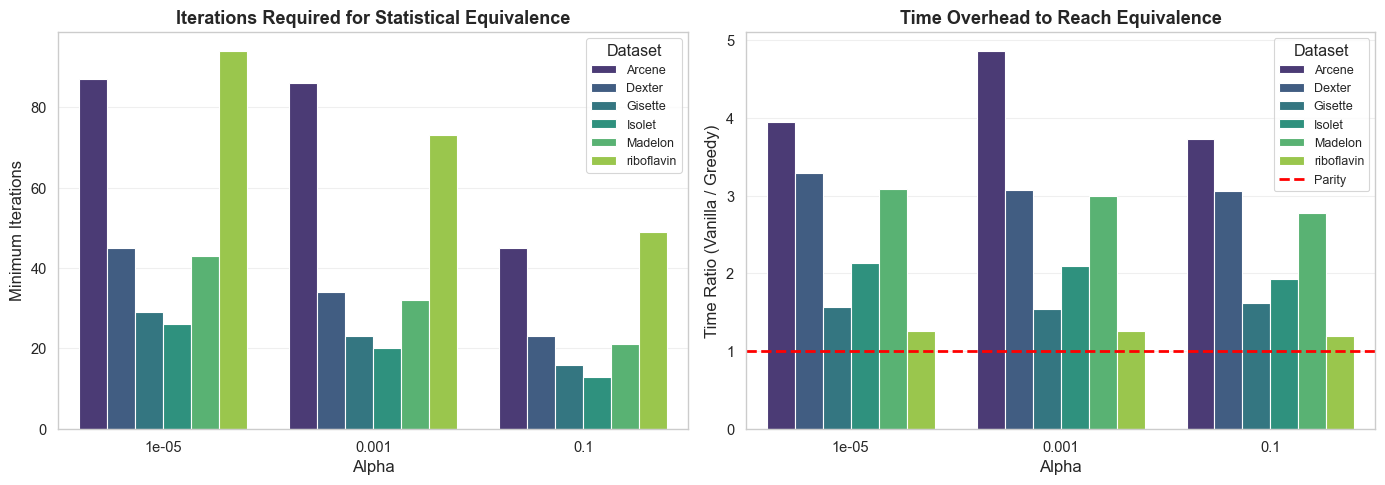

In [15]:
# Plot minimum iterations and time to equivalence
if len(equiv_achieved) > 0:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot 1: Iterations to equivalence
    equiv_plot = equiv_achieved.copy()
    equiv_plot['Alpha'] = equiv_plot['Alpha'].astype(str)
    
    sns.barplot(data=equiv_plot, x='Alpha', y='Min_Iter_Equiv', 
               hue='Dataset', ax=ax1, palette='viridis')
    ax1.set_ylabel('Minimum Iterations', fontsize=12)
    ax1.set_xlabel('Alpha', fontsize=12)
    ax1.set_title('Iterations Required for Statistical Equivalence', 
                 fontsize=13, fontweight='bold')
    ax1.legend(title='Dataset', fontsize=9)
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Plot 2: Time ratio
    sns.barplot(data=equiv_plot, x='Alpha', y='Time_Ratio', 
               hue='Dataset', ax=ax2, palette='viridis')
    ax2.set_ylabel('Time Ratio (Vanilla / Greedy)', fontsize=12)
    ax2.set_xlabel('Alpha', fontsize=12)
    ax2.set_title('Time Overhead to Reach Equivalence', 
                 fontsize=13, fontweight='bold')
    ax2.axhline(y=1, color='red', linestyle='--', linewidth=2, label='Parity')
    ax2.legend(title='Dataset', fontsize=9)
    ax2.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
else:
    print("No equivalence data to plot.")

## 9. Detailed Test Results Table

In [16]:
# Create a detailed summary table
print("\n" + "="*80)
print("DETAILED STATISTICAL TEST RESULTS")
print("="*80)
print("\nShowing all checkpoints and their equivalence status:")

display_cols = ['Dataset', 'Alpha', 'Checkpoint_ID', 'Iteration', 
                'N_Confirmed', 'Checkpoint_Mean', 'Greedy_Mean', 
                'Diff', 'P_Value_MW', 'Is_Equivalent']

display(df_tests[display_cols].round(4))


DETAILED STATISTICAL TEST RESULTS

Showing all checkpoints and their equivalence status:


,Dataset,Alpha,Checkpoint_ID,Iteration,N_Confirmed,Checkpoint_Mean,Greedy_Mean,Diff,P_Value_MW,Is_Equivalent
0,Arcene,0.0,0,1,0.0000,0.0000,0.8746,-0.8746,0.0001,False
1,Arcene,0.0,1,30,0.5000,0.2750,0.8746,-0.5996,0.0001,False
2,Arcene,0.0,2,36,1.1000,0.4809,0.8746,-0.3937,0.0002,False
3,Arcene,0.0,3,40,5.6000,0.6439,0.8746,-0.2307,0.0002,False
4,Arcene,0.0,4,44,10.6000,0.7449,0.8746,-0.1297,0.0002,False
...,...,...,...,...,...,...,...,...,...,...
1104,riboflavin,0.1,27,249,51.5556,0.5443,0.5806,-0.0364,0.3074,True
1105,riboflavin,0.1,28,354,52.1667,0.5633,0.5806,-0.0173,0.7128,True
1106,riboflavin,0.1,29,467,52.6000,0.5674,0.5806,-0.0132,0.7679,True
1107,riboflavin,0.1,30,493,54.2500,0.5615,0.5806,-0.0192,0.6354,True


## 10. Export Results

In [17]:
# Save summary results to CSV
df_min_equiv.to_csv('data/checkpoint_equivalence_summary.csv', index=False)
df_tests.to_csv('data/checkpoint_statistical_tests.csv', index=False)

print("Results exported:")
print("  - data/checkpoint_equivalence_summary.csv")
print("  - data/checkpoint_statistical_tests.csv")

OSError: Cannot save file into a non-existent directory: 'data'

## 11. Key Findings

Run this cell to generate a summary of key findings.

In [ ]:
print("\n" + "="*80)
print("KEY FINDINGS")
print("="*80)

if len(equiv_achieved) > 0:
    print(f"\n1. CONVERGENCE SPEED")
    print(f"   - Vanilla Boruta reaches statistical equivalence with Greedy")
    print(f"     in an average of {equiv_achieved['Min_Iter_Equiv'].mean():.1f} iterations")
    print(f"   - This takes {equiv_achieved['Time_Ratio'].mean():.1f}x as long as Greedy on average")
    
    print(f"\n2. FASTEST CONVERGENCE")
    fastest = equiv_achieved.loc[equiv_achieved['Min_Iter_Equiv'].idxmin()]
    print(f"   - Dataset: {fastest['Dataset']}")
    print(f"   - Alpha: {fastest['Alpha']}")
    print(f"   - Iterations: {fastest['Min_Iter_Equiv']:.0f}")
    print(f"   - Time: {fastest['Time_To_Equiv']:.2f}s")
    
    print(f"\n3. SLOWEST CONVERGENCE")
    slowest = equiv_achieved.loc[equiv_achieved['Min_Iter_Equiv'].idxmax()]
    print(f"   - Dataset: {slowest['Dataset']}")
    print(f"   - Alpha: {slowest['Alpha']}")
    print(f"   - Iterations: {slowest['Min_Iter_Equiv']:.0f}")
    print(f"   - Time: {slowest['Time_To_Equiv']:.2f}s")
    
    print(f"\n4. PRACTICAL IMPLICATIONS")
    median_ratio = equiv_achieved['Time_Ratio'].median()
    if median_ratio < 2:
        print(f"   - Vanilla converges quickly (< 2x Greedy time)")
        print(f"   - Early stopping could provide significant speedup")
    elif median_ratio < 5:
        print(f"   - Vanilla converges moderately fast (2-5x Greedy time)")
        print(f"   - Early stopping may be beneficial for large datasets")
    else:
        print(f"   - Vanilla takes significantly longer ({median_ratio:.1f}x Greedy time)")
        print(f"   - Greedy provides substantial computational advantage")
else:
    print("\nNo configurations achieved statistical equivalence.")
    print("This suggests Vanilla Boruta does not converge to Greedy's performance")
    print("within the tracked iterations.")

print("\n" + "="*80)


KEY FINDINGS

1. CONVERGENCE SPEED
   - Vanilla Boruta reaches statistical equivalence with Greedy
     in an average of 16.0 iterations
   - This takes 2.4x as long as Greedy on average

2. FASTEST CONVERGENCE
   - Dataset: Madelon
   - Alpha: 0.1
   - Iterations: 7
   - Time: 2.80s

3. SLOWEST CONVERGENCE
   - Dataset: Madelon
   - Alpha: 1e-05
   - Iterations: 22
   - Time: 9.41s

4. PRACTICAL IMPLICATIONS
   - Vanilla converges moderately fast (2-5x Greedy time)
   - Early stopping may be beneficial for large datasets

